In [ ]:
# %% [Cell 1] Setup, configuration, device
# Replicates Burrow et al. (2020, ApJ 901, 154) analysis with a Graph Neural Network only.
# No Gaussian mixture models are used anywhere in this notebook.
import os, json, zipfile, itertools, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
DEVICE = "cuda" if (HAS_TORCH and torch.cuda.is_available()) else "cpu"

CFG = dict(
    seed=42,
    val_frac=0.20,
    min_pair_n=10,
    # GNN (shared by clustering and relation discovery)
    hidden=48, emb=12, n_layers=3, dropout=0.10, pool="set2set",
    drop_node_p=0.20, epochs=400, batch=32, lr=2e-3, weight_decay=1e-4, patience=60,
    n_seeds=8,
    # clustering (paper: n = 4 for every model with pEW; n = 3 for [M_B, v_SiII])
    ks_scan=[2, 3, 4, 5, 6],
    n_branch=4, n_mbv=3,
    # relation discovery
    grid_n=60,                # points on each partial-dependence curve, spanning the FULL observed range
    importance_frac=0.25,     # parameters with at least 25% of the top GNN importance are candidates
    max_terms=3,              # at most three terms in a relation
    min_rel_gain=0.10,        # relation must beat intercept-only leave-one-out error by >= 10%
    min_rel_gain_step=0.02,   # each added term must cut leave-one-out error by >= 2%
    out_dir="/content/outputs",
)
os.makedirs(CFG["out_dir"], exist_ok=True)
np.random.seed(CFG["seed"])
if HAS_TORCH:
    torch.manual_seed(CFG["seed"])
print("torch:", HAS_TORCH, "| device:", DEVICE)


torch: True | device: cuda


In [ ]:
# %% [Cell 2] Data: Table 1 of Burrow et al. (2020), all 133 SNe Ia with errors
# Columns: name, epoch (days past B max), v_SiII (1000 km/s), error, pEW(5972) (A), error,
# pEW(6355) (A), error, M_B (mag), error, s_BV, error, survey.
# NA = not provided in the paper (s_BV is not given for the Zheng et al. 2018 subset).
TABLE1 = """
ASASSN-14hr 5.3 13.6 0.3 30.5 4.2 103.1 5.3 -19.10 0.12 0.79 0.05 CSP
ASASSN-14hu 6.9 12.5 0.2 7.4 1.2 86.7 2.8 -19.52 0.12 1.08 0.05 CSP
ASASSN-14kq -2.3 10.5 0.3 10.7 1.5 82.5 3.5 -19.44 0.11 1.19 0.05 CSP
ASASSN-14mf 5.2 9.9 0.3 23.8 2.0 103.8 3.8 -19.45 0.15 0.98 0.05 CSP
ASASSN-14my 3.6 12.0 0.3 26.1 3.9 106.9 4.3 -19.47 0.12 0.91 0.05 CSP
ASASSN-15al 5.9 11.7 0.1 19.7 4.2 81.7 5.5 -19.21 0.16 1.10 0.06 CSP
ASASSN-15ba 4.0 11.4 0.2 16.2 1.7 117.3 3.3 -19.31 0.12 0.97 0.05 CSP
ASASSN-15be 1.4 11.8 0.4 3.8 1.8 94.3 3.8 -19.37 0.12 1.20 0.05 CSP
ASASSN-15bm 1.2 10.6 0.2 9.7 2.6 72.3 4.9 -19.57 0.14 1.00 0.05 CSP
ASASSN-15dd 2.1 10.8 0.3 21.0 1.6 102.1 2.7 -19.63 0.15 0.83 0.05 CSP
ASASSN-15fr 0.2 11.7 0.2 20.7 3.7 107.4 6.1 -19.21 0.09 0.88 0.05 CSP
ASASSN-15ga 5.2 9.4 0.2 52.4 5.1 126.1 5.0 -17.95 0.40 0.50 0.06 CSP
ASASSN-15hf 1.1 11.1 0.3 21.3 2.9 83.6 2.9 -19.07 0.38 0.91 0.05 CSP
CSP14acl 5.0 10.1 0.3 16.2 3.2 116.0 5.4 -18.91 0.08 0.93 0.05 CSP
CSP15B 2.2 13.9 0.4 31.5 4.5 175.4 5.6 -19.15 0.19 0.71 0.05 CSP
CSP15aae 2.3 11.5 0.4 56.8 2.8 151.5 3.7 -17.92 0.15 0.47 0.05 CSP
LSQ11bk 1.0 12.6 0.3 5.6 1.5 98.2 3.5 -19.33 0.06 1.08 0.05 CSP
LSQ12fxd 3.8 10.9 0.3 17.9 1.9 81.0 3.4 -19.78 0.10 1.09 0.05 CSP
LSQ12gdj 1.6 10.7 0.5 8.7 1.8 36.0 2.2 -19.78 0.10 1.14 0.05 CSP
LSQ12hzj 3.2 9.8 0.3 13.5 2.2 59.1 3.7 -19.11 0.10 0.96 0.05 CSP
LSQ13aiz -6.8 14.2 0.2 17.4 2.7 133.6 3.7 -19.67 0.33 0.95 0.05 CSP
LSQ13ry 4.7 12.6 0.2 20.4 1.2 82.3 1.5 -19.15 0.09 0.86 0.05 CSP
LSQ15agh 3.8 9.9 0.6 3.5 2.6 55.3 5.0 -19.54 0.08 1.21 0.05 CSP
LSQ15aja 3.4 10.2 0.3 1.7 3.2 78.1 8.1 -19.57 0.08 1.03 0.05 CSP
PS1-14ra 3.6 11.2 0.3 34.2 3.9 124.0 6.3 -19.11 0.10 0.77 0.05 CSP
PS1-14xw 1.2 11.7 0.2 10.9 2.1 77.8 2.7 -19.72 0.13 1.06 0.05 CSP
PTF11pra 1.7 10.8 0.4 55.5 3.4 126.1 4.0 -17.31 0.24 0.40 0.05 CSP
PTF13duj 1.6 14.2 0.2 7.1 1.7 100.4 3.4 -19.35 0.17 1.19 0.05 CSP
PTF13ebh 0.6 10.8 0.2 48.3 2.3 125.0 2.7 -18.76 0.19 0.61 0.05 CSP
PTF14w 4.6 12.2 0.3 37.0 2.3 124.0 3.4 -18.80 0.13 0.73 0.05 CSP
2004ey 1.1 11.0 0.3 13.8 4.8 100.0 8.7 -19.28 0.17 1.01 0.06 CSP
2004gs 1.8 11.2 0.1 41.7 6.3 136.7 8.0 -18.86 0.11 0.69 0.06 CSP
2005M 0.5 9.2 0.4 7.4 3.7 47.5 4.5 -19.61 0.11 1.21 0.06 CSP
2005bg 2.6 10.6 0.3 7.3 3.1 105.5 9.9 -19.47 0.16 1.00 0.07 CSP
2005el 1.7 10.9 0.3 19.5 3.2 93.9 4.2 -19.14 0.15 0.84 0.06 CSP
2005eq 6.7 9.8 0.2 16.8 4.8 77.3 7.1 -19.60 0.12 1.12 0.06 CSP
2005hc -6.0 10.3 0.6 12.6 13.5 101.5 16.5 -19.46 0.10 1.19 0.06 CSP
2006D 1.8 11.2 0.2 26.4 0.9 100.4 1.1 -19.26 0.24 0.81 0.06 CSP
2006ax 0.0 10.6 0.3 9.6 2.0 92.5 2.9 -19.47 0.13 0.99 0.06 CSP
2006br 0.6 13.9 0.4 8.5 4.0 111.8 8.5 -19.52 0.27 0.91 0.07 CSP
2006hb 3.2 10.5 0.3 41.4 3.6 121.2 5.2 -18.83 0.18 0.67 0.06 CSP
2006hx 3.5 10.5 0.5 12.6 5.9 42.6 5.6 -19.64 0.13 0.99 0.06 CSP
2007S 0.1 10.1 0.2 9.2 3.2 58.7 5.4 -19.85 0.16 1.11 0.06 CSP
2007af 1.1 11.2 0.2 18.7 5.2 104.2 5.8 -19.12 0.35 0.93 0.06 CSP
2007as 3.5 12.6 0.4 18.0 2.7 138.3 4.7 -19.24 0.16 0.88 0.06 CSP
2007ba 1.7 10.8 0.2 49.1 2.8 94.9 3.0 -18.66 0.10 0.54 0.06 CSP
2007bc 1.1 10.6 0.3 29.9 1.8 100.0 2.4 -19.32 0.12 0.88 0.06 CSP
2007bd 0.3 12.7 0.3 12.3 2.0 116.4 4.4 -19.28 0.10 0.88 0.06 CSP
2007bm 3.6 10.6 0.2 24.7 1.5 101.8 2.7 -19.59 0.30 0.90 0.06 CSP
2007ca 0.9 11.0 0.3 10.5 2.0 89.9 2.4 -19.56 0.18 1.06 0.06 CSP
2007le 2.0 11.9 0.3 12.7 1.6 113.9 3.5 -19.07 0.40 1.02 0.06 CSP
2007ol 2.4 11.1 0.3 16.2 4.1 77.2 8.2 -18.87 0.06 0.70 0.07 CSP
2007on 1.4 11.2 0.1 41.3 3.9 117.4 4.2 -19.05 0.35 0.57 0.06 CSP
2007ux 1.4 11.1 0.2 54.3 7.1 124.1 9.6 -18.48 0.10 0.59 0.06 CSP
2008C 4.3 10.6 0.4 15.5 5.7 65.1 9.2 -19.38 0.21 0.95 0.07 CSP
2008O 0.4 14.4 0.7 47.6 3.4 176.3 4.7 -18.69 0.12 0.65 0.06 CSP
2008R 1.4 10.7 0.2 49.4 1.3 126.7 1.9 -18.48 0.18 0.59 0.06 CSP
2008bc 3.6 11.7 0.2 12.6 3.3 105.0 6.5 -19.45 0.16 1.05 0.06 CSP
2008bf 1.4 11.3 0.2 10.7 2.4 79.0 4.8 -19.43 0.10 1.02 0.06 CSP
2008bq 0.5 10.6 0.2 12.4 3.4 92.0 4.6 -19.74 0.16 1.16 0.06 CSP
2008cf 2.5 10.2 0.3 7.9 2.5 55.6 5.0 -19.56 0.10 1.12 0.07 CSP
2008fl 3.2 10.7 0.2 38.3 4.9 112.3 4.6 -19.38 0.18 0.85 0.06 CSP
2008fp 0.1 11.0 0.1 12.4 3.9 73.9 4.7 -19.92 0.39 1.08 0.06 CSP
2008fr 4.6 10.1 0.4 19.3 3.6 93.3 6.3 -19.35 0.12 1.06 0.06 CSP
2008fw 5.6 10.1 0.2 13.0 3.9 61.2 5.7 -19.46 0.27 1.11 0.06 CSP
2008gg 4.9 12.7 0.4 10.0 3.3 149.8 6.7 -19.47 0.15 1.11 0.07 CSP
2008gl 2.0 11.9 0.4 20.6 2.4 115.0 3.3 -19.12 0.09 0.85 0.06 CSP
2008go 0.1 13.1 0.4 8.1 2.3 154.0 4.9 -19.32 0.10 0.91 0.06 CSP
2008gp 6.8 11.0 0.3 15.4 3.0 43.7 3.1 -19.42 0.10 0.97 0.06 CSP
2008hj 6.4 13.0 0.5 16.0 2.1 103.3 3.5 -19.30 0.09 1.01 0.06 CSP
2008hu 3.7 12.4 0.3 15.9 4.7 127.0 9.4 -19.04 0.11 0.79 0.06 CSP
2008hv 1.3 10.8 0.4 21.3 2.1 96.7 3.3 -19.12 0.17 0.85 0.06 CSP
2008ia 2.3 11.4 0.4 20.0 2.4 105.9 4.2 -19.31 0.16 0.84 0.06 CSP
2009D 0.7 9.7 0.3 4.3 5.3 77.5 6.5 -19.65 0.12 1.19 0.06 CSP
2009Y 2.3 14.4 0.2 8.6 2.0 155.6 4.7 -19.62 0.23 1.19 0.06 CSP
2009aa 0.1 10.9 0.4 20.1 2.9 63.2 2.6 -19.40 0.10 0.91 0.06 CSP
2009ab 2.8 10.7 0.2 28.3 4.1 105.2 5.4 -19.04 0.23 0.87 0.06 CSP
2009ad 1.2 10.2 0.2 9.9 3.8 67.4 3.6 -19.52 0.12 1.01 0.06 CSP
2009ag 1.4 10.3 0.2 21.4 4.5 107.8 5.4 -19.26 0.31 0.96 0.06 CSP
2009cz 0.1 10.1 0.3 11.9 3.2 75.6 4.2 -19.59 0.13 1.19 0.06 CSP
2009ds 4.0 12.6 0.1 14.8 2.3 71.8 3.8 -19.65 0.13 1.12 0.06 CSP
2009le -4.7 12.5 0.2 8.2 1.5 79.2 2.6 -19.18 0.16 1.16 0.06 CSP
2011iv 5.0 10.9 0.2 40.8 2.2 88.6 2.0 -19.67 0.34 0.64 0.05 CSP
2011jh 4.8 12.8 0.2 35.0 2.8 126.1 3.9 -19.31 0.29 0.80 0.05 CSP
2012aq 6.5 11.2 0.4 27.6 2.2 105.5 3.5 -19.53 0.15 0.99 0.05 CSP
2012bl 1.4 14.7 0.3 2.3 1.2 90.5 2.4 -19.34 0.14 1.11 0.05 CSP
2012fr 0.9 12.1 0.2 6.5 1.7 70.5 3.1 -19.46 0.40 1.12 0.05 CSP
2012gm 5.8 10.4 0.3 24.1 4.0 101.5 7.5 -19.46 0.17 0.98 0.05 CSP
2012hl 3.5 12.9 0.2 13.3 3.4 142.0 7.3 -18.86 0.27 0.92 0.06 CSP
2012hr 5.6 12.6 0.3 15.3 1.3 134.7 2.1 -19.19 0.29 0.96 0.05 CSP
2012ht 1.6 10.9 0.2 27.5 1.9 115.2 2.7 -19.06 0.61 0.85 0.05 CSP
2012ij 0.2 10.8 0.3 53.3 4.0 121.5 4.7 -18.13 0.21 0.53 0.05 CSP
2013E 5.9 12.6 0.3 3.8 1.5 65.2 3.0 -19.90 0.25 1.12 0.05 CSP
2013fy 5.1 10.8 0.3 14.4 1.4 93.4 3.1 -19.67 0.12 1.19 0.05 CSP
2013gy 3.1 10.2 0.3 28.9 4.2 114.1 4.3 -19.39 0.18 0.89 0.05 CSP
2014I 1.3 11.3 0.2 23.5 3.7 98.7 4.7 -19.48 0.10 0.90 0.05 CSP
2014dn 3.0 10.4 0.6 70.9 6.2 140.1 4.7 -17.68 0.13 0.45 0.05 CSP
1998dh 1.4 12.4 0.2 26.1 2.2 124.6 2.0 -19.34 0.22 NA NA Zheng
1998dm 2.0 11.0 0.2 11.2 1.9 73.2 2.2 -18.68 0.28 NA NA Zheng
1999cp 4.0 10.6 0.2 22.7 1.4 104.6 2.4 -19.36 0.18 NA NA Zheng
1999dq 0.5 11.1 0.1 9.3 1.6 44.8 2.3 -19.82 0.15 NA NA Zheng
1999gp 0.1 11.1 0.4 8.2 2.2 53.8 3.0 -19.61 0.09 NA NA Zheng
2000cx 0.0 11.8 0.3 5.9 2.2 40.3 3.8 -19.31 0.24 NA NA Zheng
2000dn 1.8 9.7 0.3 13.3 3.2 102.4 3.6 -19.15 0.07 NA NA Zheng
2000dr 0.0 10.3 0.3 84.6 3.2 131.4 3.2 -18.52 0.11 NA NA Zheng
2000fa 0.4 11.9 0.3 10.7 2.3 83.4 4.8 -19.54 0.10 NA NA Zheng
2001V 2.5 11.4 0.1 13.2 2.1 57.0 1.9 -19.70 0.13 NA NA Zheng
2001en 0.4 12.6 0.3 9.4 1.5 135.0 3.1 -18.86 0.15 NA NA Zheng
2001ep 0.4 10.7 0.2 31.9 2.1 111.7 2.1 -19.24 0.15 NA NA Zheng
2002bo 2.0 13.4 0.2 10.5 5.1 150.4 9.3 -19.31 0.29 NA NA Zheng
2002cr 0.3 10.1 0.1 19.3 1.8 104.6 2.0 -19.34 0.18 NA NA Zheng
2002dj 5.0 14.0 0.3 6.3 1.3 151.0 2.3 -19.26 0.21 NA NA Zheng
2002dl 6.6 12.5 0.4 40.2 4.5 90.1 4.9 -18.28 0.12 NA NA Zheng
2002eb 3.0 10.1 0.2 9.9 2.1 65.0 4.1 -19.60 0.08 NA NA Zheng
2002er 0.0 12.0 0.0 24.2 0.9 115.2 1.2 -19.34 0.21 NA NA Zheng
2002fk 1.4 9.8 0.3 18.6 1.7 80.7 2.2 -19.40 0.24 NA NA Zheng
2002ha 1.0 11.3 0.3 30.6 2.6 111.3 2.8 -19.16 0.14 NA NA Zheng
2002he 0.6 12.6 0.2 20.2 1.1 118.3 1.5 -19.01 0.09 NA NA Zheng
2003W 0.4 15.2 0.5 6.4 1.7 108.2 3.5 -19.44 0.10 NA NA Zheng
2003Y 2.0 11.3 0.4 71.8 8.2 104.1 5.9 -17.48 0.14 NA NA Zheng
2003cg 0.2 11.1 0.3 24.0 2.5 96.1 3.1 -19.49 0.32 NA NA Zheng
2003gn 3.3 13.2 0.9 40.8 9.3 146.8 10.3 -18.81 0.11 NA NA Zheng
2003gt 4.8 11.3 0.4 33.6 3.6 76.8 4.1 -19.47 0.13 NA NA Zheng
2004at 0.2 10.7 0.2 10.5 1.9 92.6 2.3 -19.46 0.09 NA NA Zheng
2004dt 0.0 16.0 0.0 21.5 1.9 167.0 3.0 -19.83 0.10 NA NA Zheng
2005cf 0.0 10.3 0.3 17.0 1.1 89.7 1.2 -19.41 0.25 NA NA Zheng
2005de 1.7 10.7 0.3 30.2 3.2 102.9 3.5 -19.06 0.13 NA NA Zheng
2006cp 3.7 14.9 0.5 15.3 2.4 159.0 3.0 -19.27 0.11 NA NA Zheng
2006gr 0.3 11.3 0.4 3.3 2.5 65.0 4.2 -19.41 0.09 NA NA Zheng
2006le 2.4 11.4 0.2 13.0 2.4 93.3 5.2 -19.85 0.11 NA NA Zheng
2006lf 2.6 11.7 0.1 25.7 3.0 100.4 4.4 -19.39 0.16 NA NA Zheng
2007ci 0.8 12.3 0.4 50.0 2.6 126.4 2.8 -18.58 0.11 NA NA Zheng
2008ec 0.4 10.8 0.7 36.7 2.8 119.3 3.1 -19.21 0.13 NA NA Zheng
"""


def load_burrow_table1():
    rows = []
    for line in TABLE1.strip().splitlines():
        f = line.split()
        rows.append(f)
    cols = ["name", "epoch", "vsi", "err_vsi_k", "pew5972", "err_pew5972", "pew6355", "err_pew6355",
            "M_B", "err_M_B", "sBV", "err_sBV", "survey"]
    df = pd.DataFrame(rows, columns=cols)
    for c in cols:
        if c not in ("name", "survey"):
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["vsi"] = df["vsi"] * 1000.0                 # 1000 km/s -> km/s
    df["err_vsi"] = df.pop("err_vsi_k") * 1000.0
    df["sn_type"] = "Ia"
    return df.reset_index(drop=True)


DATA = load_burrow_table1()
print("SNe:", len(DATA), "| CSP:", (DATA.survey == "CSP").sum(), "| Zheng et al.:", (DATA.survey == "Zheng").sum())
print("s_BV available:", DATA["sBV"].notna().sum())
assert len(DATA) == 133 and (DATA.survey == "CSP").sum() == 97
DATA.head()


SNe: 133 | CSP: 97 | Zheng et al.: 36
s_BV available: 97


,name,epoch,vsi,pew5972,err_pew5972,pew6355,err_pew6355,M_B,err_M_B,sBV,err_sBV,survey,err_vsi,sn_type
0,ASASSN-14hr,5.3,13600.0,30.5,4.2,103.1,5.3,-19.10,0.12,0.79,0.05,CSP,300.0,Ia
1,ASASSN-14hu,6.9,12500.0,7.4,1.2,86.7,2.8,-19.52,0.12,1.08,0.05,CSP,200.0,Ia
2,ASASSN-14kq,-2.3,10500.0,10.7,1.5,82.5,3.5,-19.44,0.11,1.19,0.05,CSP,300.0,Ia
3,ASASSN-14mf,5.2,9900.0,23.8,2.0,103.8,3.8,-19.45,0.15,0.98,0.05,CSP,300.0,Ia
4,ASASSN-14my,3.6,12000.0,26.1,3.9,106.9,4.3,-19.47,0.12,0.91,0.05,CSP,300.0,Ia


In [ ]:
# %% [Cell 3] Statistics helpers and graph inputs (no mixture models)
def pairwise_stats(df, nodes):
    keys = ["pearson", "spearman", "kendall", "mi", "n_pairs"]
    out = {k: pd.DataFrame(np.nan, index=nodes, columns=nodes) for k in keys}
    for i, a in enumerate(nodes):
        for j, b in enumerate(nodes):
            sub = df[[a, b]].dropna()
            n = len(sub)
            out["n_pairs"].iloc[i, j] = n
            if i == j:
                for k in ["pearson", "spearman", "kendall"]:
                    out[k].iloc[i, j] = 1.0
                continue
            if n < 4:
                continue
            x, y = sub[a].values, sub[b].values
            out["pearson"].iloc[i, j] = stats.pearsonr(x, y)[0]
            out["spearman"].iloc[i, j] = stats.spearmanr(x, y)[0]
            out["kendall"].iloc[i, j] = stats.kendalltau(x, y)[0]
            if n >= 5:
                out["mi"].iloc[i, j] = mutual_info_regression(x.reshape(-1, 1), y, n_neighbors=3, random_state=0)[0]
    return out


def edge_weights(S, min_n):
    s = S["spearman"].astype(float).to_numpy(copy=True)
    n = S["n_pairs"].astype(float).to_numpy()
    W = np.where(n >= min_n, np.abs(np.nan_to_num(s)), 0.0)
    np.fill_diagonal(W, 0.0)
    return W


def edge_features(S):
    return np.nan_to_num(np.stack([S[k].astype(float).to_numpy() for k in ["pearson", "spearman", "mi"]], -1))


def build_graph_tensors(df, nodes, ref):
    """Node features per SN: standardised value, relative error, presence flag. Missing values are masked."""
    vals = df[nodes].to_numpy(float)
    rv = ref[nodes].to_numpy(float)
    mu = np.nanmean(rv, 0)
    sd = np.nanstd(rv, 0) + 1e-12
    mask = ~np.isnan(vals)
    z = np.where(mask, (vals - mu) / sd, 0.0)
    errs = np.column_stack([df["err_" + p].to_numpy(float) if ("err_" + p) in df.columns
                            else np.full(len(df), np.nan) for p in nodes])
    with np.errstate(all="ignore"):
        rel = np.abs(errs) / (np.abs(vals) + 1e-12)
    rel = np.clip(np.nan_to_num(np.where(mask, rel, 0.0)), 0, 1)
    X = np.stack([z, rel, mask.astype(float)], -1).astype(np.float32)
    return dict(X=X, mask=mask.astype(np.float32), mu=mu, sd=sd)


def ols_loocv(X, y):
    X = np.column_stack([np.ones(len(y)), X])
    beta = np.linalg.pinv(X) @ y
    H = X @ np.linalg.pinv(X.T @ X) @ X.T
    e = y - X @ beta
    loo = e / (1 - np.diag(H) + 1e-12)
    n, p = X.shape
    rss = np.sum(e ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    return dict(beta=beta, rmse_fit=np.sqrt(rss / n), rmse_loo=np.sqrt(np.mean(loo ** 2)),
                r2=1 - rss / ss_tot if ss_tot > 0 else np.nan, aic=n * np.log(rss / n + 1e-12) + 2 * p)


BASIS = {
    "x": (lambda x: x, lambda x: np.ones_like(x, bool)),
    "x^2": (lambda x: x ** 2, lambda x: np.ones_like(x, bool)),
    "x^3": (lambda x: x ** 3, lambda x: np.ones_like(x, bool)),
    "sqrt(x)": (lambda x: np.sqrt(x), lambda x: x >= 0),
    "log(x)": (lambda x: np.log(x), lambda x: x > 0),
    "1/x": (lambda x: 1.0 / x, lambda x: x != 0),
}
for _k in (0.5, 1.0, 2.0, 3.0, 4.0, 6.0):
    BASIS[f"exp(-{_k:g}x)"] = (lambda x, k=_k: np.exp(-k * x), lambda x: np.ones_like(x, bool))
TEMPLATE = {"x": "{p}", "x^2": "{p}^2", "x^3": "{p}^3", "sqrt(x)": "sqrt({p})", "log(x)": "log({p})",
            "1/x": "1/{p}"}
for _k in (0.5, 1.0, 2.0, 3.0, 4.0, 6.0):
    TEMPLATE[f"exp(-{_k:g}x)"] = f"exp(-{_k:g}*{{p}})"


def term_label(form, p):
    return TEMPLATE[form].format(p=p)


def best_curve_form(x, y):
    """Choose the functional form that best describes a curve, by AIC.
    The linear form is preferred when its AIC is within 2 of the best one."""
    best, lin = None, None
    for name, (f, ok) in BASIS.items():
        m = ok(x) & np.isfinite(y)
        if m.sum() < 8:
            continue
        Xc = f(x[m])
        if not np.all(np.isfinite(Xc)) or np.std(Xc) < 1e-12:
            continue
        A = np.column_stack([np.ones(m.sum()), Xc])
        beta, *_ = np.linalg.lstsq(A, y[m], rcond=None)
        rss = np.sum((y[m] - A @ beta) ** 2) + 1e-12
        n = m.sum()
        cand = dict(form=name, aic=n * np.log(rss / n) + 4.0, beta=beta,
                    r2=1 - rss / np.sum((y[m] - y[m].mean()) ** 2))
        if name == "x":
            lin = cand
        if best is None or cand["aic"] < best["aic"]:
            best = cand
    if best is None:
        return None
    if lin is not None and lin["aic"] - best["aic"] < 2.0:
        return lin
    return best


def kernel_fit(x, y, grid=None, n_grid=200):
    """Smooth fit to all points: Gaussian kernel regression with bandwidth chosen by leave-one-out CV.
    Used to draw the trend through the scatter plots (no assumed functional form)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    sd = np.std(x) + 1e-12
    cands = sd * np.array([0.08, 0.12, 0.18, 0.25, 0.35, 0.5])
    best = None
    for bw in cands:
        Wm = np.exp(-0.5 * ((x[:, None] - x[None, :]) / bw) ** 2)
        np.fill_diagonal(Wm, 0.0)
        pred = (Wm @ y) / (Wm.sum(1) + 1e-12)
        err = np.sqrt(np.mean((y - pred) ** 2))
        if best is None or err < best[1]:
            best = (bw, err)
    bw = best[0]
    if grid is None:
        grid = np.linspace(x.min(), x.max(), n_grid)
    W = np.exp(-0.5 * ((grid[:, None] - x[None, :]) / bw) ** 2)
    return grid, (W @ y) / (W.sum(1) + 1e-12), bw


def loocv_rmse(X, y):
    return ols_loocv(X, y)["rmse_loo"]


def cluster_names_branch(df, labels):
    """Name clusters as Branch groups from their centroids (Branch et al. 2006 definitions):
    BL = largest pEW(6355); CL = largest pEW(5972) among the rest; SS = smallest pEW in both; CN = remaining."""
    cents = {c: (df.loc[labels == c, "pew5972"].mean(), df.loc[labels == c, "pew6355"].mean()) for c in np.unique(labels)}
    names = {}
    bl = max(cents, key=lambda c: cents[c][1]); names[bl] = "BL"
    rest = [c for c in cents if c != bl]
    cl = max(rest, key=lambda c: cents[c][0]); names[cl] = "CL"
    rest = [c for c in rest if c != cl]
    if rest:
        ss = min(rest, key=lambda c: cents[c][0] + cents[c][1]); names[ss] = "SS"
        for c in rest:
            if c != ss:
                names[c] = "CN"
    return np.array([names[c] for c in labels])


def cluster_names_mbv(df, labels):
    """Name [M_B, v_SiII] groups as in the paper: Fast = highest v_SiII; Dim = faintest of the rest; Main = remaining."""
    cents = {c: (df.loc[labels == c, "vsi"].mean(), df.loc[labels == c, "M_B"].mean()) for c in np.unique(labels)}
    names = {}
    fast = max(cents, key=lambda c: cents[c][0]); names[fast] = "Fast"
    rest = [c for c in cents if c != fast]
    if rest:
        dim = max(rest, key=lambda c: cents[c][1]); names[dim] = "Dim"
        for c in rest:
            if c != dim:
                names[c] = "Main"
    return np.array([names[c] for c in labels])


In [ ]:
# %% [Cell 4] Graph neural network (edge-conditioned message passing + Set2Set; thesis Eqs. 9.4-9.11)
if HAS_TORCH:
    class EdgeConv(nn.Module):
        def __init__(self, d_in, d_out, d_edge):
            super().__init__()
            self.d_in, self.d_out = d_in, d_out
            self.self_lin = nn.Linear(d_in, d_out)
            self.edge_net = nn.Sequential(nn.Linear(d_edge, 32), nn.ReLU(), nn.Linear(32, d_in * d_out))

        def forward(self, h, A, E):
            K = E.shape[0]
            W = self.edge_net(E).view(K, K, self.d_in, self.d_out)
            msg = torch.einsum("bwi,vwio->bvwo", h, W)
            agg = torch.einsum("bvw,bvwo->bvo", A, msg)
            return torch.relu(self.self_lin(h) + agg)

    class Set2Set(nn.Module):
        def __init__(self, d, steps=3):
            super().__init__()
            self.d, self.steps = d, steps
            self.lstm = nn.LSTMCell(2 * d, d)

        def forward(self, h, mask):
            B = h.shape[0]
            q_star = h.new_zeros(B, 2 * self.d)
            q = h.new_zeros(B, self.d)
            c = h.new_zeros(B, self.d)
            for _ in range(self.steps):
                q, c = self.lstm(q_star, (q, c))
                e = (h * q[:, None, :]).sum(-1).masked_fill(mask == 0, -1e9)
                a = torch.softmax(e, dim=1) * mask
                r = (a[..., None] * h).sum(1)
                q_star = torch.cat([q, r], dim=-1)
            return q_star

    class GNN(nn.Module):
        """Shared encoder. head='embed' returns the SN embedding h_G; head='regress' returns one scalar."""
        def __init__(self, d_node, d_edge, hidden, emb, n_layers, dropout, pool, head, K):
            super().__init__()
            dims = [d_node] + [hidden] * n_layers
            self.convs = nn.ModuleList([EdgeConv(dims[i], dims[i + 1], d_edge) for i in range(n_layers)])
            self.norms = nn.ModuleList([nn.LayerNorm(hidden) for _ in range(n_layers)])
            self.drop = nn.Dropout(dropout)
            self.pool, self.head_type = pool, head
            pooled = 2 * hidden if pool == "set2set" else hidden
            if pool == "set2set":
                self.s2s = Set2Set(hidden)
            self.readout = nn.Linear(pooled, emb)
            if head == "embed":
                self.decoder = nn.Sequential(nn.Linear(emb, hidden), nn.ReLU(), nn.Linear(hidden, K))
            else:
                self.regressor = nn.Sequential(nn.Linear(emb, emb), nn.ReLU(), nn.Linear(emb, 1))

        def encode(self, X, A, E, mask):
            h = X
            for conv, norm in zip(self.convs, self.norms):
                h = norm(conv(h, A, E))
                h = self.drop(h) * mask[..., None]
            if self.pool == "set2set":
                g = self.s2s(h, mask)
            else:
                g = (h * mask[..., None]).sum(1) / mask.sum(1, keepdim=True).clamp(min=1.0)
            return self.readout(g)

        def forward(self, X, A, E, mask):
            z = self.encode(X, A, E, mask)
            if self.head_type == "embed":
                return z, self.decoder(z)
            return z, self.regressor(z).squeeze(-1)

    def _masked_mse(pred, target, mask):
        return (((pred - target) ** 2) * mask).sum() / mask.sum().clamp(min=1.0)

    def _adj(W, m):
        return W[None] * m[:, :, None] * m[:, None, :]

    # ---- self-supervised encoder: denoising reconstruction of every node (for clustering) ----
    def train_embedding_gnn(G, W, E, cfg, seed, tr_rows, va_rows):
        torch.manual_seed(seed); np.random.seed(seed)
        X = torch.tensor(G["X"], device=DEVICE)
        M = torch.tensor(G["mask"], device=DEVICE)
        Wt = torch.tensor(W, dtype=torch.float32, device=DEVICE)
        Et = torch.tensor(E, dtype=torch.float32, device=DEVICE)
        tr = torch.tensor(tr_rows, device=DEVICE); va = torch.tensor(va_rows, device=DEVICE)
        model = GNN(X.shape[2], Et.shape[-1], cfg["hidden"], cfg["emb"], cfg["n_layers"],
                    cfg["dropout"], cfg["pool"], "embed", X.shape[1]).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
        idx_tr = torch.where(tr)[0]
        best, best_state, bad = np.inf, None, 0
        for ep in range(cfg["epochs"]):
            model.train()
            perm = idx_tr[torch.randperm(len(idx_tr), device=DEVICE)]
            for s in range(0, len(perm), cfg["batch"]):
                b = perm[s:s + cfg["batch"]]
                Xb, Mb = X[b], M[b]
                keep = (torch.rand_like(Mb) > cfg["drop_node_p"]).float()
                m_in = Mb * keep
                _, rec = model(Xb * m_in[..., None], _adj(Wt, m_in), Et, m_in)
                loss = _masked_mse(rec, Xb[..., 0], Mb)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                opt.step()
            sched.step()
            model.eval()
            with torch.no_grad():
                Xv, Mv = X[va], M[va]
                _, rv = model(Xv, _adj(Wt, Mv), Et, Mv)
                vloss = float(_masked_mse(rv, Xv[..., 0], Mv))
            if vloss < best - 1e-5:
                best, best_state, bad = vloss, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if bad >= cfg["patience"]:
                    break
        model.load_state_dict(best_state); model.eval()
        with torch.no_grad():
            z, _ = model(X, _adj(Wt, M), Et, M)
        return z.cpu().numpy(), best

    # ---- supervised relation learner: target node hidden from input ----
    def _rel_inputs(Xb, Mb, Wt, cfg, train):
        m_in = Mb.clone()
        m_in[:, 0] = 0.0
        if train:
            keep = (torch.rand_like(Mb) > cfg["drop_node_p"]).float()
            keep[:, 0] = 1.0
            m_in = m_in * keep
        return Xb * m_in[..., None], _adj(Wt, m_in), m_in

    def train_relation_gnn(G, W, E, cfg, seed, tr_mask, va_mask):
        torch.manual_seed(seed); np.random.seed(seed)
        X = torch.tensor(G["X"], device=DEVICE)
        M = torch.tensor(G["mask"], device=DEVICE)
        Y = X[:, 0, 0]
        Wt = torch.tensor(W, dtype=torch.float32, device=DEVICE)
        Et = torch.tensor(E, dtype=torch.float32, device=DEVICE)
        tr = torch.tensor(tr_mask, device=DEVICE); va = torch.tensor(va_mask, device=DEVICE)
        model = GNN(X.shape[2], Et.shape[-1], cfg["hidden"], cfg["emb"], cfg["n_layers"],
                    cfg["dropout"], cfg["pool"], "regress", X.shape[1]).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
        idx_tr = torch.where(tr)[0]
        best, best_state, bad = np.inf, None, 0
        for ep in range(cfg["epochs"]):
            model.train()
            perm = idx_tr[torch.randperm(len(idx_tr), device=DEVICE)]
            for s in range(0, len(perm), cfg["batch"]):
                b = perm[s:s + cfg["batch"]]
                Xi, A, mi = _rel_inputs(X[b], M[b], Wt, cfg, True)
                loss = ((model(Xi, A, Et, mi)[1] - Y[b]) ** 2).mean()
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                opt.step()
            sched.step()
            model.eval()
            with torch.no_grad():
                Xi, A, mi = _rel_inputs(X[va], M[va], Wt, cfg, False)
                vloss = float(((model(Xi, A, Et, mi)[1] - Y[va]) ** 2).mean())
            if vloss < best - 1e-5:
                best, best_state, bad = vloss, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if bad >= cfg["patience"]:
                    break
        model.load_state_dict(best_state); model.eval()
        return model, best

    def _predict(model, X, M, Wt, Et):
        with torch.no_grad():
            Xi, A, mi = _rel_inputs(X, M, Wt, None, False)
            return model(Xi, A, Et, mi)[1]

    def partial_dependence(models, G, W, E, node, grid_raw, rows):
        X = torch.tensor(G["X"][rows], device=DEVICE)
        M = torch.tensor(G["mask"][rows], device=DEVICE)
        Wt = torch.tensor(W, dtype=torch.float32, device=DEVICE)
        Et = torch.tensor(E, dtype=torch.float32, device=DEVICE)
        mu, sd = G["mu"][node], G["sd"][node]
        out = []
        for gv in grid_raw:
            X2 = X.clone(); X2[:, node, 0] = float((gv - mu) / sd); X2[:, node, 1] = 0.0; X2[:, node, 2] = 1.0
            M2 = M.clone(); M2[:, node] = 1.0
            out.append(np.mean([float(_predict(m, X2, M2, Wt, Et).mean()) for m in models]))
        return np.array(out) * G["sd"][0] + G["mu"][0]

    def occlusion_importance(models, G, W, E, rows, nodes):
        X = torch.tensor(G["X"][rows], device=DEVICE)
        M = torch.tensor(G["mask"][rows], device=DEVICE)
        Wt = torch.tensor(W, dtype=torch.float32, device=DEVICE)
        Et = torch.tensor(E, dtype=torch.float32, device=DEVICE)
        Yt = X[:, 0, 0]
        obs = M[:, 0] > 0

        def mse(Mx, Xx, sel):
            return np.mean([float((((_predict(m, Xx, Mx, Wt, Et) - Yt) ** 2)[sel]).mean()) for m in models])

        imp = {}
        for j in range(1, len(nodes)):
            sel = (M[:, j] > 0) & obs
            if int(sel.sum()) < 5:
                imp[nodes[j]] = 0.0
                continue
            base = mse(M, X, sel)
            X2 = X.clone(); X2[:, j, :] = 0.0
            M2 = M.clone(); M2[:, j] = 0.0
            imp[nodes[j]] = max(mse(M2, X2, sel) - base, 0.0)
        return imp


def pca2(Z, seed):
    return PCA(n_components=min(2, Z.shape[1], Z.shape[0] - 1), random_state=seed).fit_transform(Z)


def fallback_embed(G, cfg):
    """Used only when torch is absent (offline check of the plotting code). Not the GNN."""
    flat = np.concatenate([G["X"][..., 0] * G["mask"], G["mask"]], 1)
    Z = PCA(n_components=min(cfg["emb"], flat.shape[0] - 1, flat.shape[1]), random_state=cfg["seed"]).fit_transform(flat)
    return Z, np.nan


In [ ]:
# %% [Cell 5] GNN clustering (no mixture models). The GNN embeds each SN; spectral clustering on the
# seed-ensemble co-association matrix gives the groups. Silhouette and seed stability choose and check n.
from sklearn.metrics import silhouette_score


def gnn_cluster(df, nodes, cfg, ks_final, title=""):
    d = df.reset_index(drop=True)
    G = build_graph_tensors(d, nodes, d)
    S = pairwise_stats(d, nodes)
    W = edge_weights(S, cfg["min_pair_n"])
    E = edge_features(S)
    N = len(d)
    rng = np.random.default_rng(cfg["seed"])
    perm = rng.permutation(N)
    n_va = max(int(round(cfg["val_frac"] * N)), 5)
    va_mask = np.zeros(N, bool); va_mask[perm[:n_va]] = True
    tr_mask = ~va_mask
    embeds, vals = [], []
    if HAS_TORCH:
        for s in range(cfg["n_seeds"]):
            z, v = train_embedding_gnn(G, W, E, cfg, cfg["seed"] + s, tr_mask, va_mask)
            embeds.append(z); vals.append(v)
    else:
        z, v = fallback_embed(G, cfg); embeds, vals = [z], [v]
    best = int(np.nanargmin(vals)) if HAS_TORCH else 0
    ZP = pca2(embeds[best], cfg["seed"])
    seed_pca = [pca2(z, cfg["seed"]) for z in embeds]
    scan_rows, labels_by_k, conf_by_k = [], {}, {}
    all_ks = sorted(set(cfg["ks_scan"]) | set(ks_final))
    for k in all_ks:
        seed_labels = []
        for P in seed_pca:
            seed_labels.append(SpectralClustering(n_clusters=k, affinity="nearest_neighbors",
                               n_neighbors=min(7, N - 1), random_state=cfg["seed"],
                               assign_labels="kmeans").fit_predict(P))
        C = np.zeros((N, N))
        for lab in seed_labels:
            C += (lab[:, None] == lab[None, :])
        C /= len(seed_labels)
        cons = SpectralClustering(n_clusters=k, affinity="precomputed", random_state=cfg["seed"]).fit_predict(C)
        sil = silhouette_score(ZP, cons) if len(set(cons)) > 1 else np.nan
        stab = np.mean([adjusted_rand_score(cons, lab) for lab in seed_labels])
        scan_rows.append(dict(k=k, silhouette=sil, seed_stability_ARI=stab))
        labels_by_k[k] = cons
        # membership strength: how strongly each SN co-clusters with each group (membership strength, not a mixture-model posterior)
        P_mem = np.column_stack([C[:, cons == c].mean(1) for c in range(k)])
        P_mem = P_mem / P_mem.sum(1, keepdims=True)
        conf_by_k[k] = P_mem
    scan = pd.DataFrame(scan_rows)
    print(f"[{title}] seeds={len(embeds)} | best validation MSE={vals[best]:.4f}" if HAS_TORCH else f"[{title}] fallback embedding")
    return dict(ZP=ZP, scan=scan, labels=labels_by_k, membership=conf_by_k, embeds=embeds, G=G, W=W, E=E, S=S)


FEATURE_SETS = {
    "pEW2D": (["pew5972", "pew6355"], "branch"),
    "pEW3D_vSi": (["vsi", "pew5972", "pew6355"], "branch"),
    "pEW3D_MB": (["M_B", "pew5972", "pew6355"], "branch"),
    "FULL4D": (["M_B", "vsi", "pew5972", "pew6355"], "branch"),
    "MBvSi2D": (["M_B", "vsi"], "mbv"),
}
RUN = {}
for key, (nodes, kind) in FEATURE_SETS.items():
    k_final = CFG["n_branch"] if kind == "branch" else CFG["n_mbv"]
    r = gnn_cluster(DATA, nodes, CFG, [k_final], title=key)
    labs = r["labels"][k_final]
    r["names"] = cluster_names_branch(DATA, labs) if kind == "branch" else cluster_names_mbv(DATA, labs)
    r["k"] = k_final
    RUN[key] = r
    print(key, "clusters:", pd.Series(r["names"]).value_counts().to_dict())


[pEW2D] seeds=8 | best validation MSE=0.0035
pEW2D clusters: {'CN': 65, 'SS': 32, 'CL': 22, 'BL': 14}
[pEW3D_vSi] seeds=8 | best validation MSE=0.0209
pEW3D_vSi clusters: {'CL': 51, 'CN': 44, 'SS': 21, 'BL': 17}
[pEW3D_MB] seeds=8 | best validation MSE=0.0769
pEW3D_MB clusters: {'CL': 64, 'SS': 28, 'CN': 22, 'BL': 19}
[FULL4D] seeds=8 | best validation MSE=0.0723
FULL4D clusters: {'SS': 40, 'BL': 38, 'CN': 37, 'CL': 18}
[MBvSi2D] seeds=8 | best validation MSE=0.2495
MBvSi2D clusters: {'Dim': 56, 'Fast': 39, 'Main': 38}


=== fig02a_silhouette.png ===


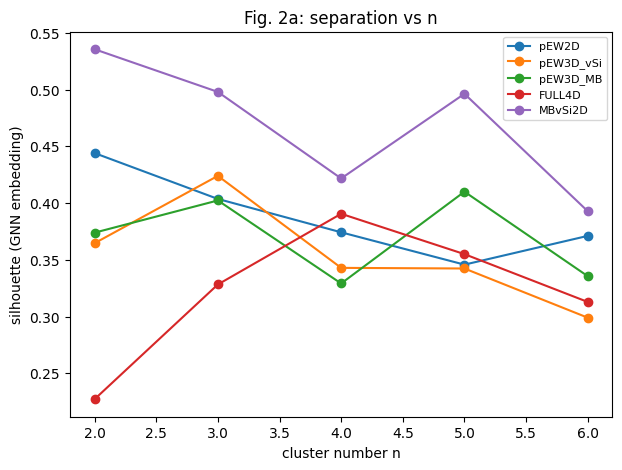

=== fig02b_stability.png ===


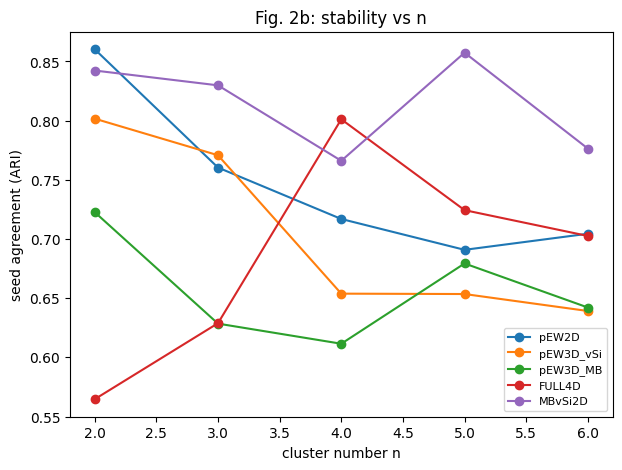

=== fig03_branch_data.png ===


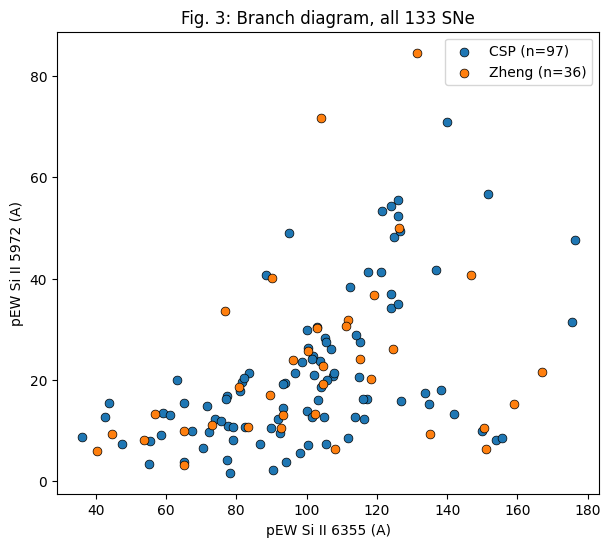

=== fig04_branch_gnn2d.png ===


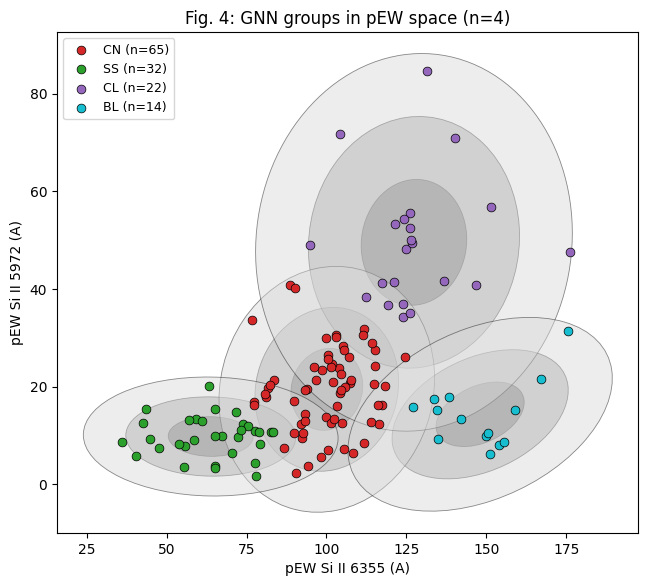

=== fig05a_branch_3d_vsi.png ===


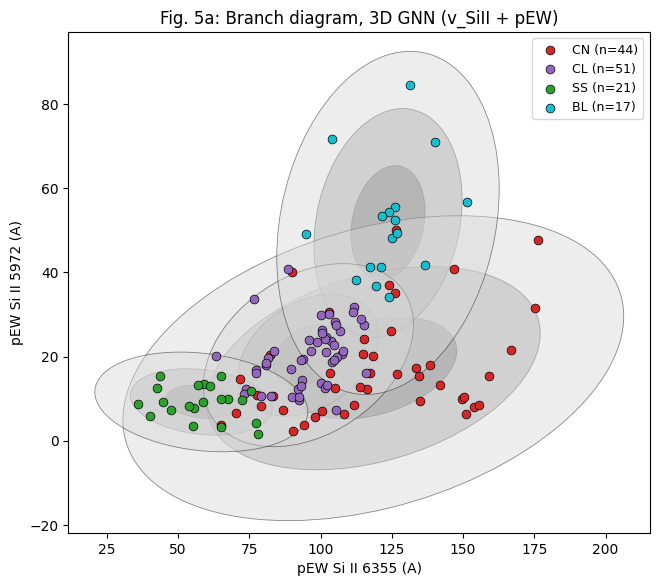

=== fig05b_pew5972_vsi_3d.png ===


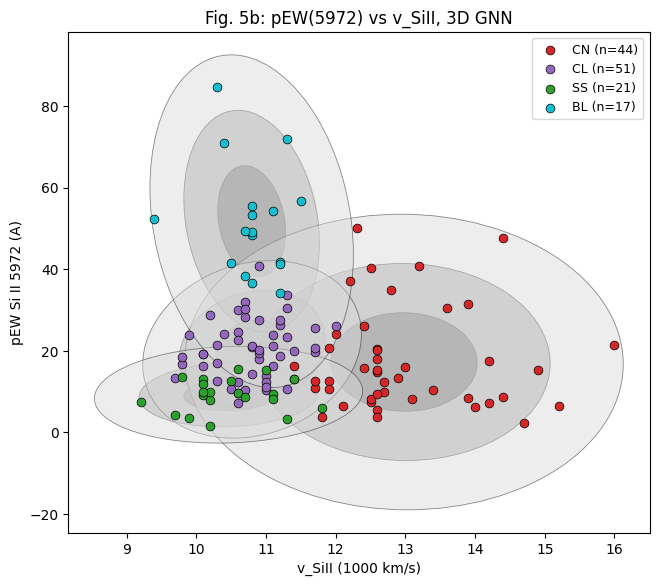

=== fig06a_branch_3d_mb.png ===


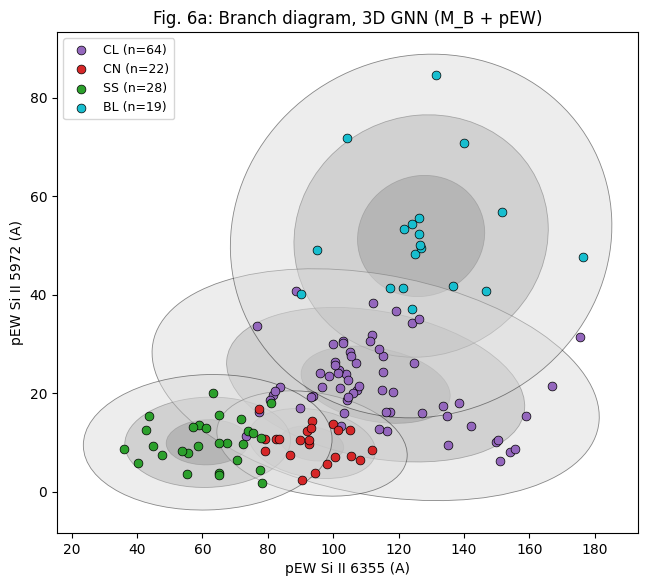

=== fig06b_mb_pew5972_3d.png ===


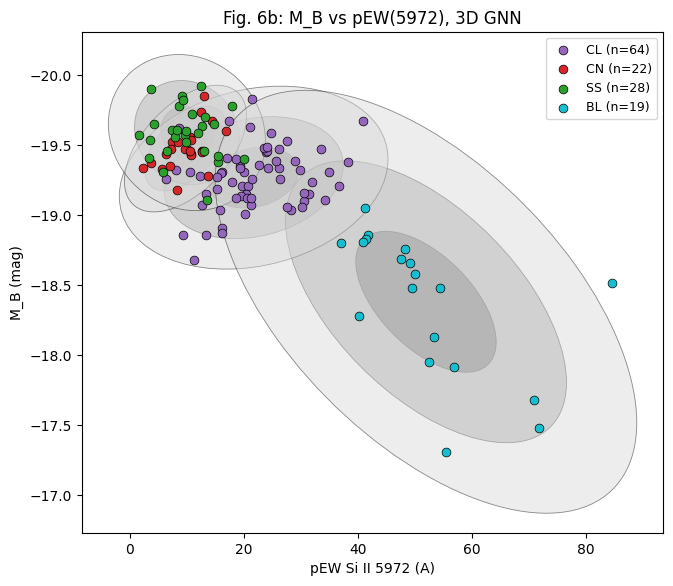

=== fig07_mb_pew5972_quadratic.png ===


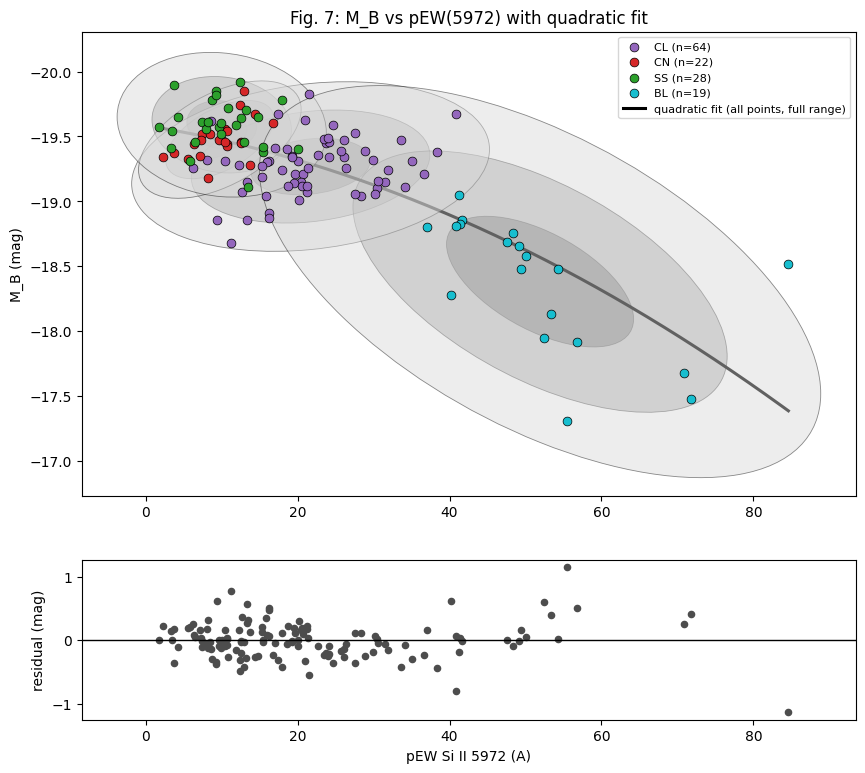

Quadratic coefficients (x^2, x, intercept): [ 1.962879e-04  9.359625e-03 -1.958445e+01]
RMS residual (mag): 0.291
=== fig08a_branch_4d.png ===


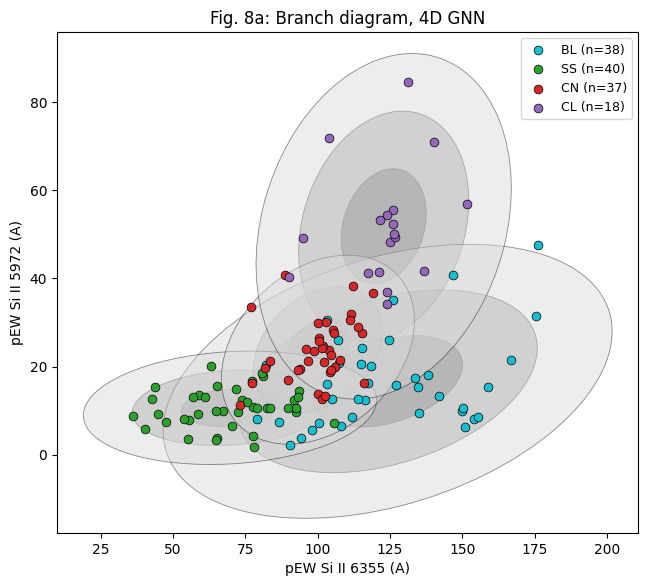

=== fig08b_pew5972_vsi_4d.png ===


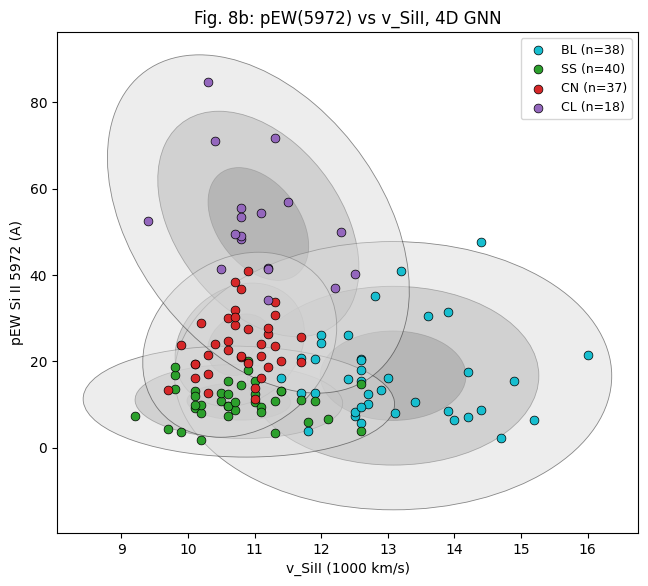

=== fig08c_mb_pew5972_4d.png ===


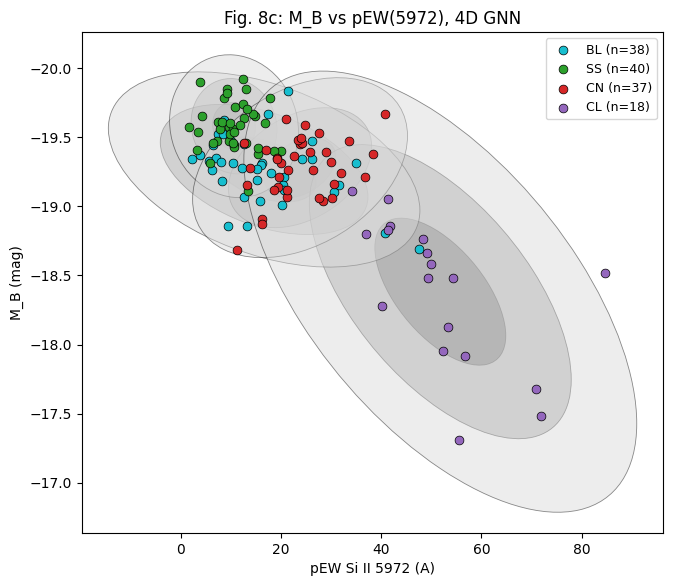


Table 3 analogue: 112 of 133 SNe change group between models


In [ ]:
# %% [Cell 6] Figures 2-8 and Table 3. Every figure is shown and saved in order (numbered in the file names).
BR_COL = {"CN": "tab:red", "SS": "tab:green", "CL": "tab:purple", "BL": "tab:cyan",
          "Main": "tab:green", "Dim": "tab:purple", "Fast": "tab:cyan"}
SHADE = {1: "0.25", 2: "0.55", 3: "0.85"}   # dark / medium / light grey = 1 / 2 / 3 sigma


def show(fig, name):
    """Save each figure to disk, display it in Colab, then close it. One figure per call."""
    print(f"=== {name} ===")
    fig.savefig(os.path.join(CFG["out_dir"], name), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def zones_by_name(ax, x, y, names, title=None, xlabel=None, ylabel=None, invert_y=False, invert_x=False):
    """Group points coloured by name, with 1, 2, 3 sigma zones from each group's members (moment-based)."""
    x = np.asarray(x, float); y = np.asarray(y, float); names = np.asarray(names)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y, names = x[ok], y[ok], names[ok]
    for nm in pd.unique(names):
        m = names == nm
        P = np.column_stack([x[m], y[m]])
        if m.sum() >= 4:
            mu_ = P.mean(0)
            cov = np.cov(P.T) + 1e-9 * np.eye(2)
            w, V = np.linalg.eigh(cov)
            o = w.argsort()[::-1]; w, V = w[o], V[:, o]
            ang = np.degrees(np.arctan2(V[1, 0], V[0, 0]))
            for s in (3, 2, 1):
                ax.add_patch(Ellipse(mu_, 2 * s * np.sqrt(max(w[0], 0)), 2 * s * np.sqrt(max(w[1], 0)),
                                     angle=ang, facecolor=SHADE[s], edgecolor="k", alpha=0.45, lw=0.6, zorder=s))
        ax.scatter(P[:, 0], P[:, 1], s=40, edgecolor="k", lw=0.5, zorder=5,
                   color=BR_COL.get(nm, "k"), label=f"{nm} (n={m.sum()})")
    ax.legend(fontsize=9, loc="best")
    ax.autoscale_view()
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    if invert_y: ax.invert_yaxis()
    if invert_x: ax.invert_xaxis()


PEW_X, PEW_Y = "pEW Si II 6355 (A)", "pEW Si II 5972 (A)"

# Figure 2: GNN scan (replaces the paper's Delta BIC, which needs a mixture model)
fig, ax = plt.subplots(figsize=(7, 5))
for key, r in RUN.items():
    ax.plot(r["scan"]["k"], r["scan"]["silhouette"], "o-", label=key)
ax.set(xlabel="cluster number n", ylabel="silhouette (GNN embedding)", title="Fig. 2a: separation vs n")
ax.legend(fontsize=8); show(fig, "fig02a_silhouette.png")

fig, ax = plt.subplots(figsize=(7, 5))
for key, r in RUN.items():
    ax.plot(r["scan"]["k"], r["scan"]["seed_stability_ARI"], "o-", label=key)
ax.set(xlabel="cluster number n", ylabel="seed agreement (ARI)", title="Fig. 2b: stability vs n")
ax.legend(fontsize=8); show(fig, "fig02b_stability.png")

# Figure 3: Branch diagram of the full sample
fig, ax = plt.subplots(figsize=(7, 6))
for sv, col in [("CSP", "tab:blue"), ("Zheng", "tab:orange")]:
    m = DATA.survey == sv
    ax.scatter(DATA.loc[m, "pew6355"], DATA.loc[m, "pew5972"], s=40, color=col, edgecolor="k", lw=0.5,
               label=f"{sv} (n={m.sum()})")
ax.set(xlabel=PEW_X, ylabel=PEW_Y, title="Fig. 3: Branch diagram, all 133 SNe"); ax.legend()
show(fig, "fig03_branch_data.png")

# Figure 4: GNN groups in pEW space, n = 4
fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.pew6355, DATA.pew5972, RUN["pEW2D"]["names"],
              "Fig. 4: GNN groups in pEW space (n=4)", PEW_X, PEW_Y)
show(fig, "fig04_branch_gnn2d.png")

# Figure 5a / 5b: 3D model with v_SiII
fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.pew6355, DATA.pew5972, RUN["pEW3D_vSi"]["names"],
              "Fig. 5a: Branch diagram, 3D GNN (v_SiII + pEW)", PEW_X, PEW_Y)
show(fig, "fig05a_branch_3d_vsi.png")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.vsi / 1000, DATA.pew5972, RUN["pEW3D_vSi"]["names"],
              "Fig. 5b: pEW(5972) vs v_SiII, 3D GNN", "v_SiII (1000 km/s)", PEW_Y)
show(fig, "fig05b_pew5972_vsi_3d.png")

# Figure 6a / 6b: 3D model with M_B
fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.pew6355, DATA.pew5972, RUN["pEW3D_MB"]["names"],
              "Fig. 6a: Branch diagram, 3D GNN (M_B + pEW)", PEW_X, PEW_Y)
show(fig, "fig06a_branch_3d_mb.png")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.pew5972, DATA.M_B, RUN["pEW3D_MB"]["names"],
              "Fig. 6b: M_B vs pEW(5972), 3D GNN", PEW_Y, "M_B (mag)", invert_y=True)
show(fig, "fig06b_mb_pew5972_3d.png")

# Figure 7: M_B vs pEW(5972), with the quadratic the paper fits, and its residuals
dq = DATA.dropna(subset=["M_B", "pew5972"]).reset_index(drop=True)
coef = np.polyfit(dq.pew5972, dq.M_B, 2)
xs = np.linspace(dq.pew5972.min(), dq.pew5972.max(), 300)
fig = plt.figure(figsize=(9, 8))
ax1 = fig.add_axes([0.1, 0.36, 0.86, 0.58]); ax2 = fig.add_axes([0.1, 0.08, 0.86, 0.20], sharex=ax1)
zones_by_name(ax1, dq.pew5972, dq.M_B, np.asarray(RUN["pEW3D_MB"]["names"])[dq.index.to_numpy()],
              "Fig. 7: M_B vs pEW(5972) with quadratic fit", None, "M_B (mag)", invert_y=True)
ax1.plot(xs, np.polyval(coef, xs), "k-", lw=2.2, label="quadratic fit (all points, full range)")
ax1.legend(fontsize=8)
res7 = dq.M_B - np.polyval(coef, dq.pew5972)
ax2.scatter(dq.pew5972, res7, s=20, color="0.3"); ax2.axhline(0, color="k", lw=1)
ax2.set(xlabel=PEW_Y, ylabel="residual (mag)")
show(fig, "fig07_mb_pew5972_quadratic.png")
print("Quadratic coefficients (x^2, x, intercept):", np.array2string(coef, precision=6))
print("RMS residual (mag):", round(float(np.sqrt(np.mean(res7 ** 2))), 3))

# Figure 8a / 8b / 8c: 4D model
fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.pew6355, DATA.pew5972, RUN["FULL4D"]["names"],
              "Fig. 8a: Branch diagram, 4D GNN", PEW_X, PEW_Y)
show(fig, "fig08a_branch_4d.png")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.vsi / 1000, DATA.pew5972, RUN["FULL4D"]["names"],
              "Fig. 8b: pEW(5972) vs v_SiII, 4D GNN", "v_SiII (1000 km/s)", PEW_Y)
show(fig, "fig08b_pew5972_vsi_4d.png")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.pew5972, DATA.M_B, RUN["FULL4D"]["names"],
              "Fig. 8c: M_B vs pEW(5972), 4D GNN", PEW_Y, "M_B (mag)", invert_y=True)
show(fig, "fig08c_mb_pew5972_4d.png")

# Table 3: group changes between the 2D, 3D (v_SiII) and 4D GNN models
tab3 = pd.DataFrame({"SN": DATA.name, "2D": RUN["pEW2D"]["names"], "3D_vSi": RUN["pEW3D_vSi"]["names"],
                     "4D": RUN["FULL4D"]["names"]})
changed = tab3[(tab3["2D"] != tab3["4D"]) | (tab3["3D_vSi"] != tab3["4D"])]
print(f"\nTable 3 analogue: {len(changed)} of {len(tab3)} SNe change group between models")
tab3.to_csv(os.path.join(CFG["out_dir"], "table3_group_changes.csv"), index=False)


=== fig09_mb_vsi_data.png ===


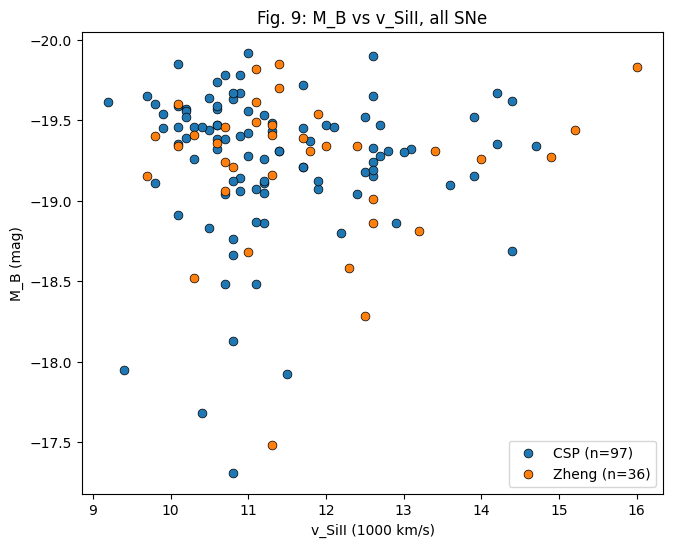

=== fig10_mbvsi_gnn.png ===


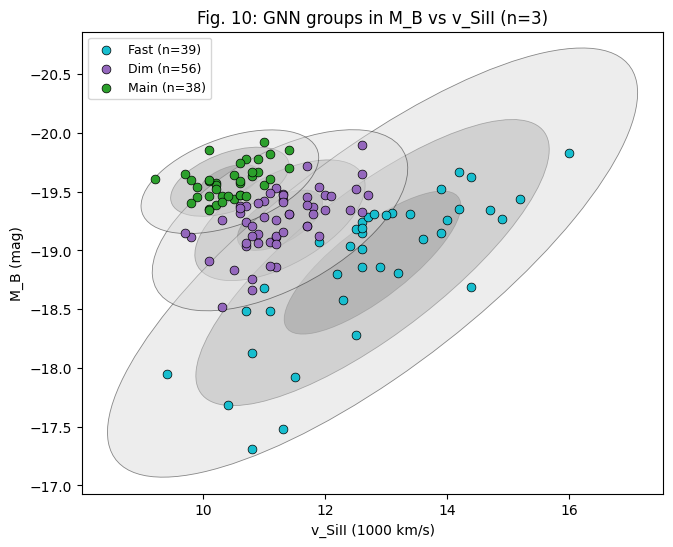

=== fig11_branch_by_mbvsi.png ===


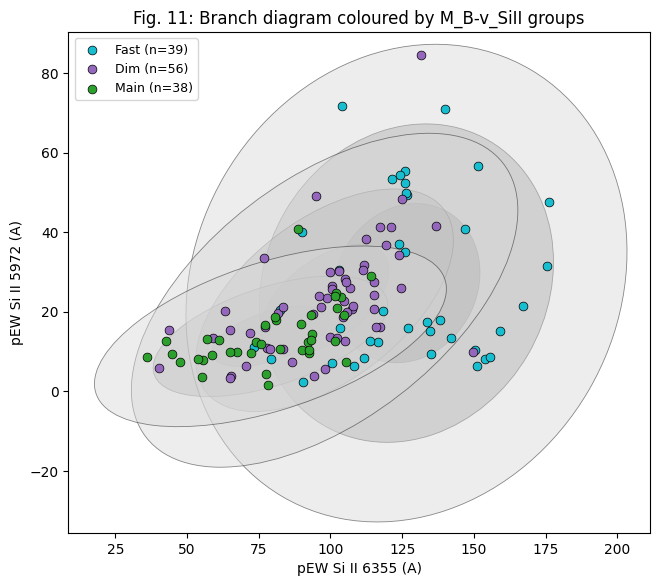

=== fig16_mbvsi_4d.png ===


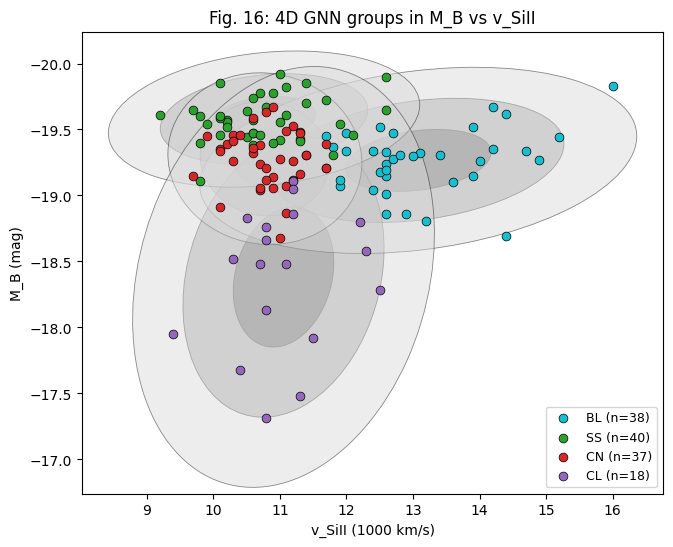

=== fig17a_mb_sbv_branch.png ===


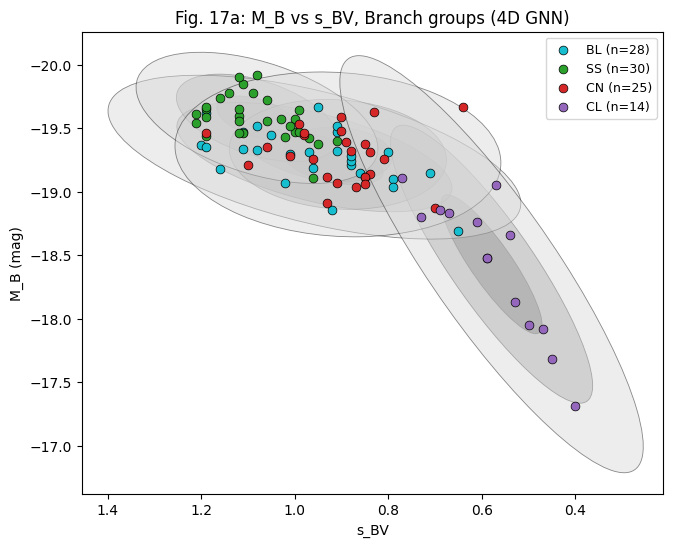

=== fig17b_mb_sbv_mbvsi.png ===


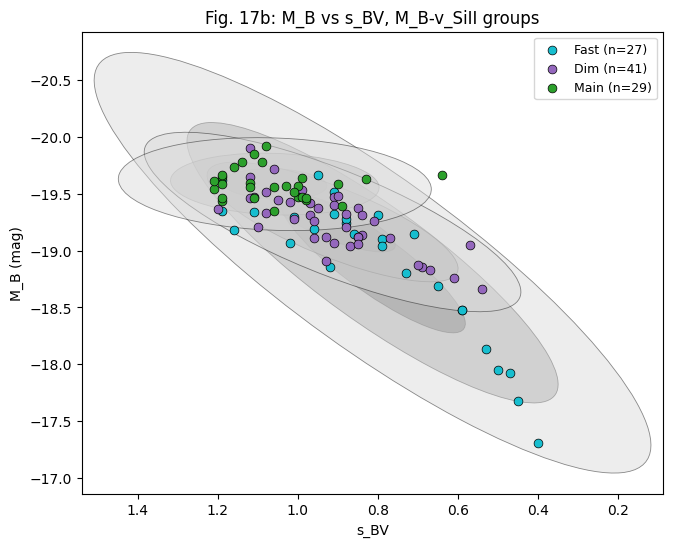

=== fig18_branch_sbv.png ===


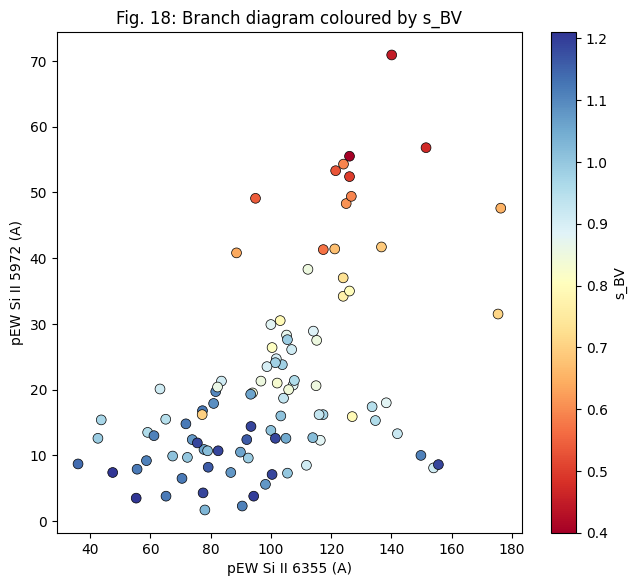

=== fig19_pew5972_sbv.png ===


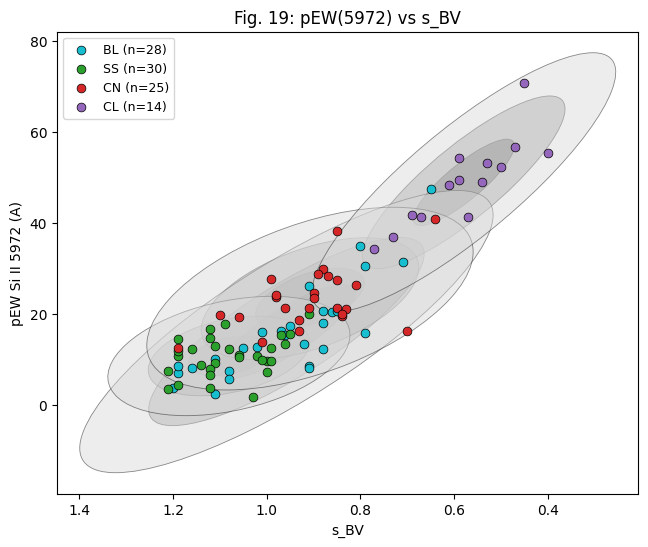

In [ ]:
# %% [Cell 7] Figures 9-11, 16 (M_B vs v_SiII) and 17-19 (s_BV). Each figure is shown and saved in order.
fig, ax = plt.subplots(figsize=(7.5, 6))
for sv, col in [("CSP", "tab:blue"), ("Zheng", "tab:orange")]:
    m = DATA.survey == sv
    ax.scatter(DATA.loc[m, "vsi"] / 1000, DATA.loc[m, "M_B"], s=40, color=col, edgecolor="k", lw=0.5,
               label=f"{sv} (n={m.sum()})")
ax.invert_yaxis(); ax.set(xlabel="v_SiII (1000 km/s)", ylabel="M_B (mag)", title="Fig. 9: M_B vs v_SiII, all SNe")
ax.legend(); show(fig, "fig09_mb_vsi_data.png")

fig, ax = plt.subplots(figsize=(7.5, 6))
zones_by_name(ax, DATA.vsi / 1000, DATA.M_B, RUN["MBvSi2D"]["names"],
              "Fig. 10: GNN groups in M_B vs v_SiII (n=3)", "v_SiII (1000 km/s)", "M_B (mag)", invert_y=True)
show(fig, "fig10_mbvsi_gnn.png")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
zones_by_name(ax, DATA.pew6355, DATA.pew5972, RUN["MBvSi2D"]["names"],
              "Fig. 11: Branch diagram coloured by M_B-v_SiII groups", PEW_X, PEW_Y)
show(fig, "fig11_branch_by_mbvsi.png")

fig, ax = plt.subplots(figsize=(7.5, 6))
zones_by_name(ax, DATA.vsi / 1000, DATA.M_B, RUN["FULL4D"]["names"],
              "Fig. 16: 4D GNN groups in M_B vs v_SiII", "v_SiII (1000 km/s)", "M_B (mag)", invert_y=True)
show(fig, "fig16_mbvsi_4d.png")

# s_BV: available for the 97 CSP SNe only
C = DATA[DATA.sBV.notna()].copy().reset_index(drop=True)
C["names4d"] = np.asarray(RUN["FULL4D"]["names"])[DATA.index[DATA.sBV.notna()].to_numpy()]
C["namesmbv"] = np.asarray(RUN["MBvSi2D"]["names"])[DATA.index[DATA.sBV.notna()].to_numpy()]

fig, ax = plt.subplots(figsize=(7.5, 6))
zones_by_name(ax, C.sBV, C.M_B, C.names4d, "Fig. 17a: M_B vs s_BV, Branch groups (4D GNN)",
              "s_BV", "M_B (mag)", invert_y=True, invert_x=True)
show(fig, "fig17a_mb_sbv_branch.png")

fig, ax = plt.subplots(figsize=(7.5, 6))
zones_by_name(ax, C.sBV, C.M_B, C.namesmbv, "Fig. 17b: M_B vs s_BV, M_B-v_SiII groups",
              "s_BV", "M_B (mag)", invert_y=True, invert_x=True)
show(fig, "fig17b_mb_sbv_mbvsi.png")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
sc = ax.scatter(C.pew6355, C.pew5972, c=C.sBV, cmap="RdYlBu", s=50, edgecolor="k", lw=0.5)
fig.colorbar(sc, ax=ax, label="s_BV")
ax.set(xlabel=PEW_X, ylabel=PEW_Y, title="Fig. 18: Branch diagram coloured by s_BV")
show(fig, "fig18_branch_sbv.png")

fig, ax = plt.subplots(figsize=(7.5, 6))
zones_by_name(ax, C.sBV, C.pew5972, C.names4d, "Fig. 19: pEW(5972) vs s_BV", "s_BV", PEW_Y, invert_x=True)
show(fig, "fig19_pew5972_sbv.png")



[all 133 SNe] n=133 | GNN validation RMSE = 0.258 mag
  importance (GNN occlusion): {'pew5972': 0.5237, 'pew6355': 0.4272, 'vsi': 0.14}
  candidates passed to selection: ['vsi', 'pew5972', 'pew6355']
  relation: M_B = -19.725 +0.022*[pew5972]
   FOUND 

[97 CSP SNe with s_BV] n=97 | GNN validation RMSE = 0.183 mag
  importance (GNN occlusion): {'sBV': 0.3609, 'pew6355': 0.0745, 'pew5972': 0.0352, 'vsi': 0.0107}
  candidates passed to selection: ['sBV']
  relation: M_B = -19.637 +11.070*[exp(-4*sBV)]
   FOUND 
=== relall_vsi.png ===


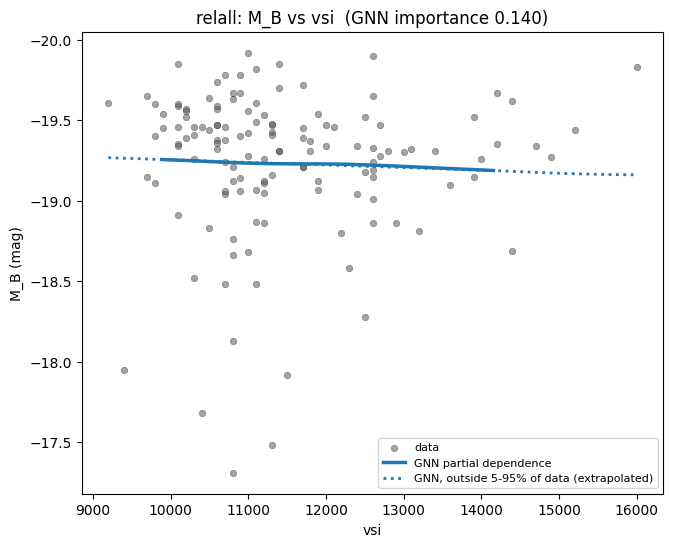

=== relall_pew5972.png ===


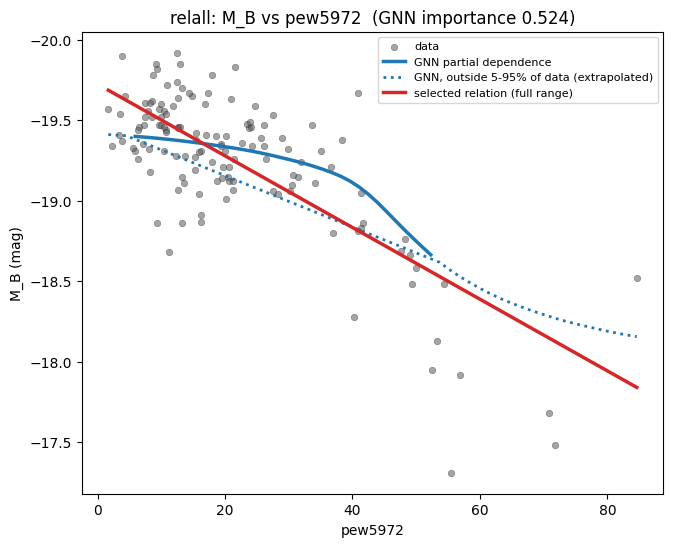

=== relall_pew6355.png ===


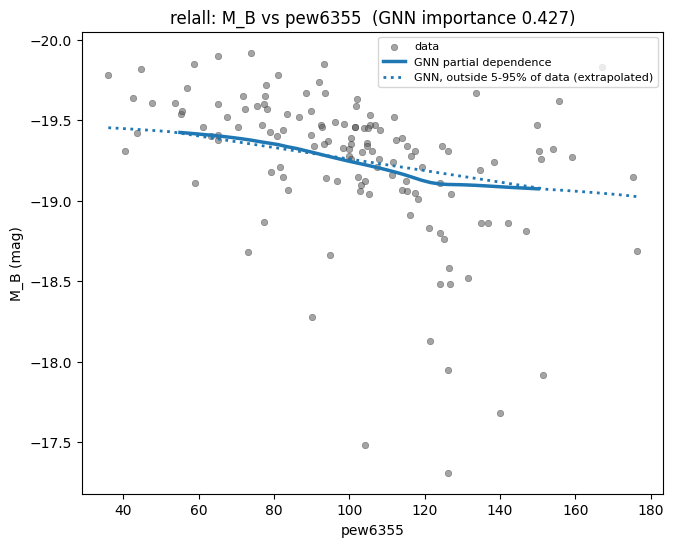

=== relsbv_sBV.png ===


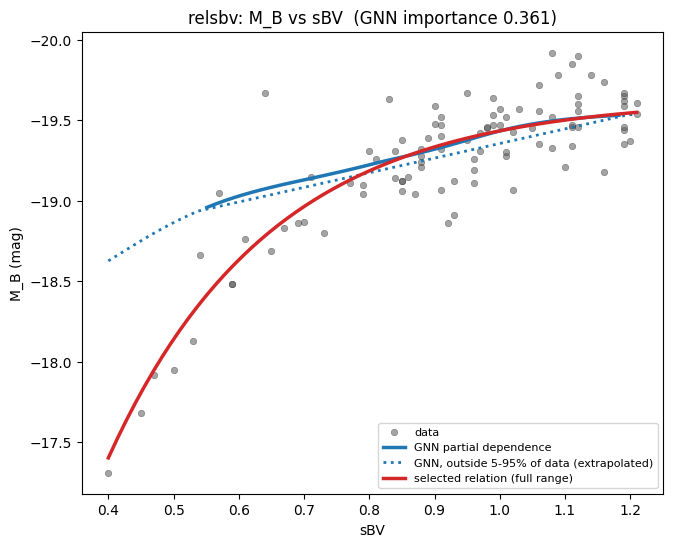

=== relsbv_pew5972.png ===


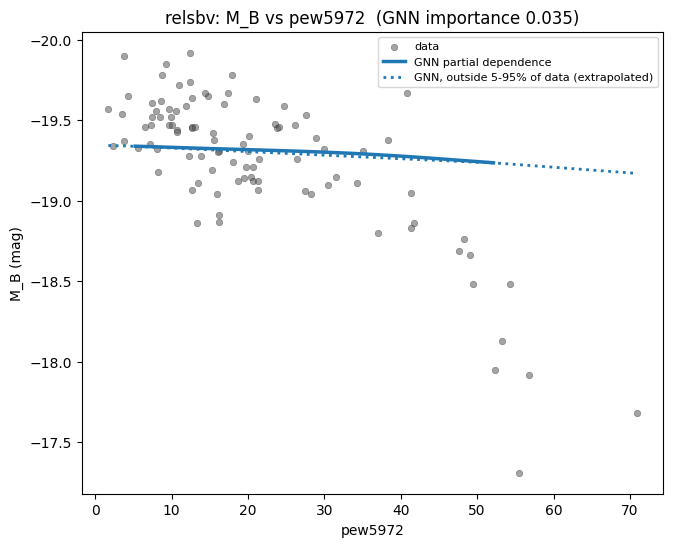

=== relsbv_vsi.png ===


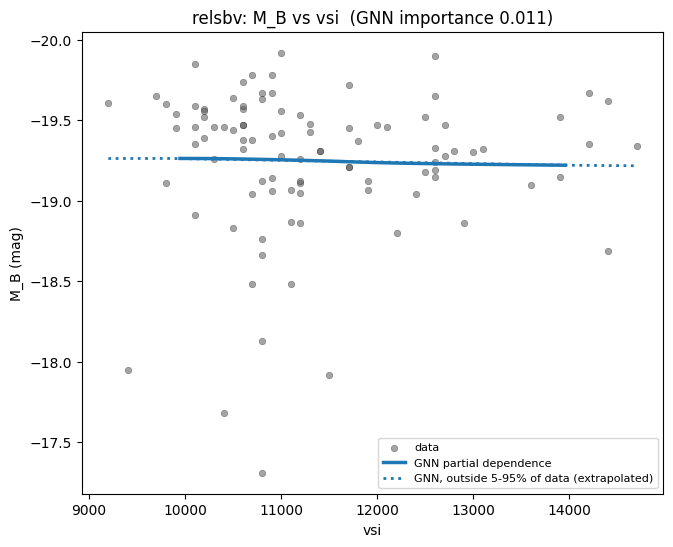

=== relsbv_pew6355.png ===


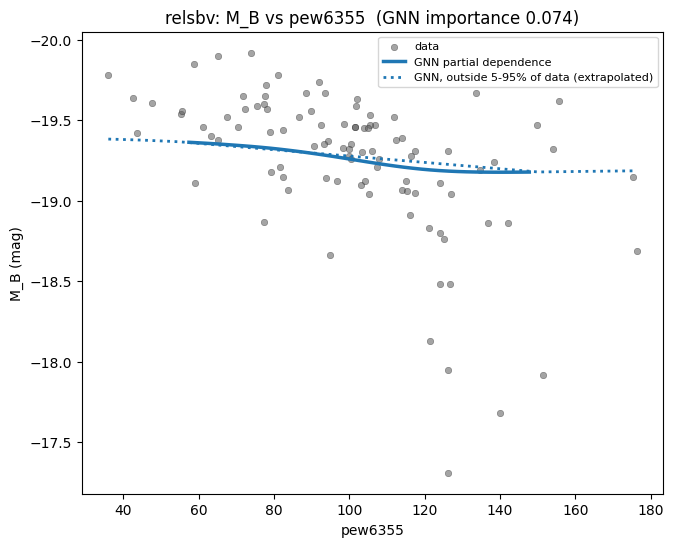


Paper-style quadratic in pEW(5972): LOOCV RMSE = 0.336 mag
Selected relation, all 133 SNe: LOOCV RMSE = 0.307 mag (intercept-only 0.459, gain 33.1%)
Selected relation, 97 CSP with s_BV: LOOCV RMSE = 0.214 mag (intercept-only 0.458, gain 53.3%)
=== relall_observed_vs_predicted.png ===


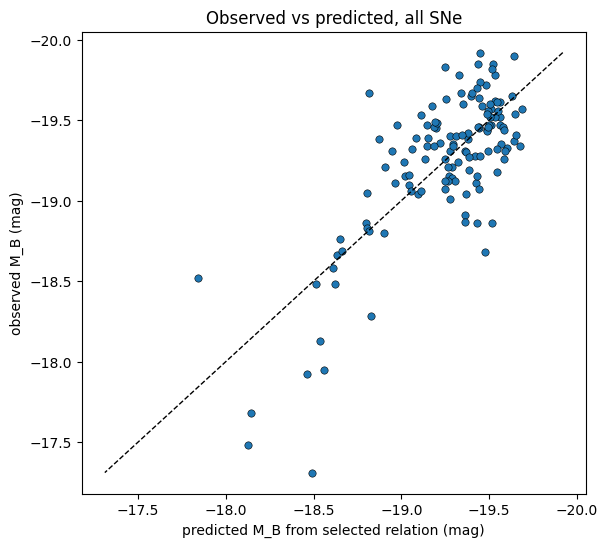


[Branch group BL] n=38 | GNN validation RMSE = 0.144 mag
  importance (GNN occlusion): {'pew5972': 0.4258, 'pew6355': 0.1315, 'vsi': 0.0997}
  candidates passed to selection: ['pew5972', 'pew6355']
  relation: M_B = -19.327 +0.000*[pew5972^3]
   FOUND 
=== relgroup_BL_vsi.png ===


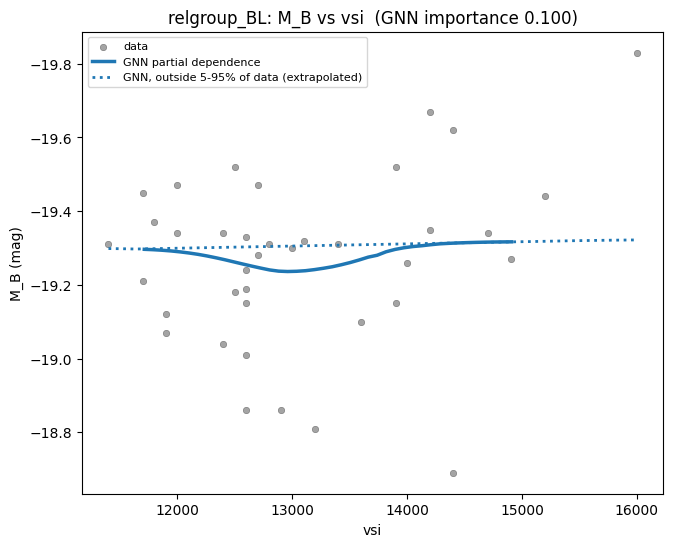

=== relgroup_BL_pew5972.png ===


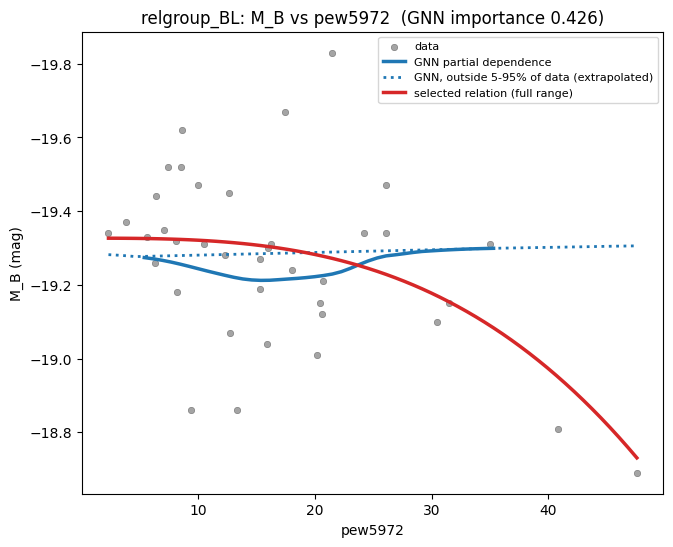

=== relgroup_BL_pew6355.png ===


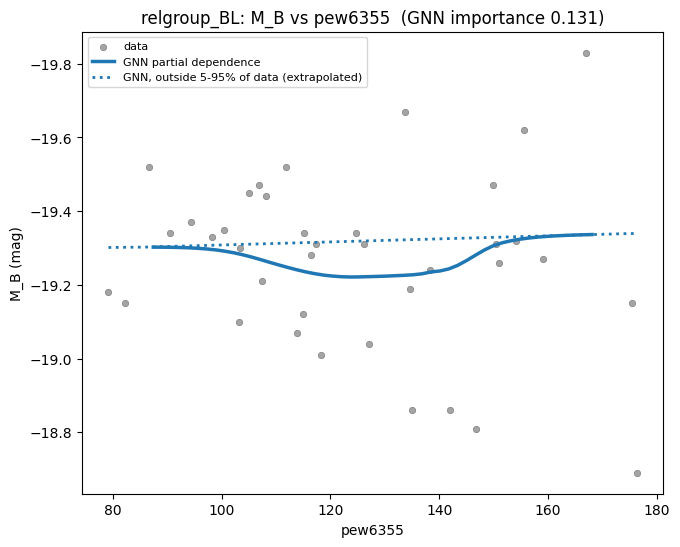


[Branch group SS] n=40 | GNN validation RMSE = 0.226 mag
  importance (GNN occlusion): {'pew5972': 0.2573, 'pew6355': 0.1057, 'vsi': 0.0724}
  candidates passed to selection: ['vsi', 'pew5972', 'pew6355']
  relation: M_B = -19.334 -0.000*[vsi^2]
   NOT FOUND - gain 2.1% below 10%
=== relgroup_SS_vsi.png ===


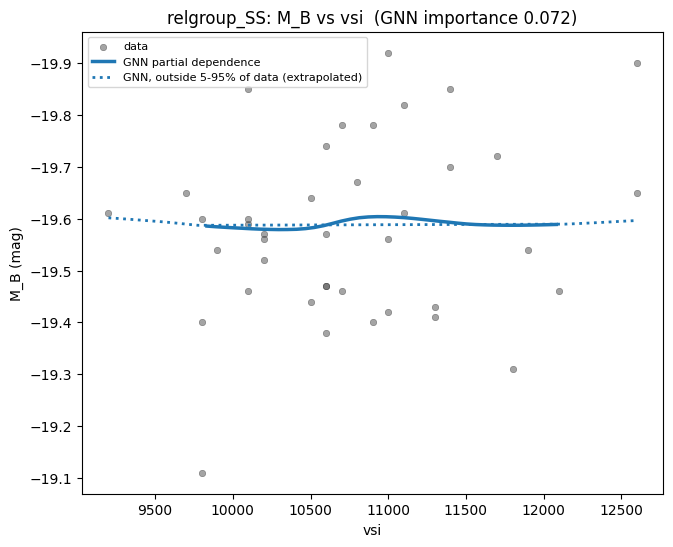

=== relgroup_SS_pew5972.png ===


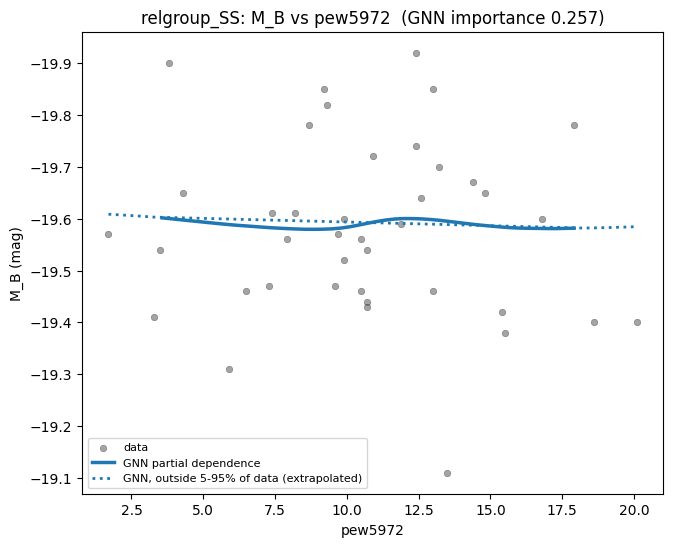

=== relgroup_SS_pew6355.png ===


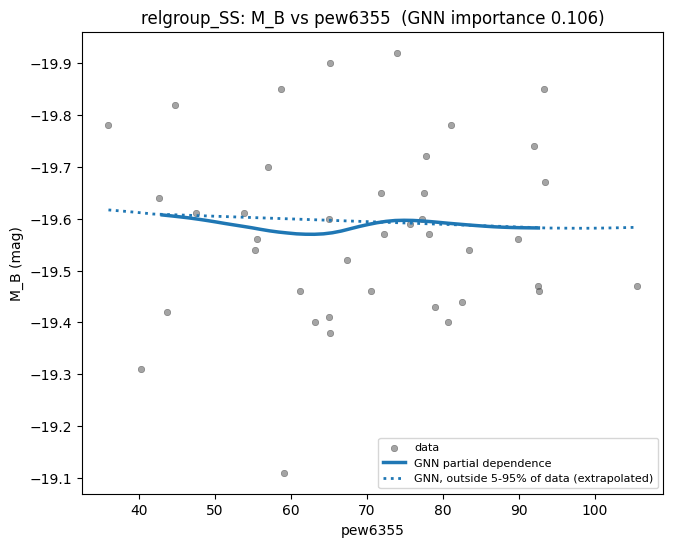


[Branch group CN] n=37 | GNN validation RMSE = 0.162 mag
  importance (GNN occlusion): {'pew6355': 0.0832, 'pew5972': 0.0831, 'vsi': 0.0165}
  candidates passed to selection: ['pew5972', 'pew6355']
  relation: M_B = -19.297 +3244375340.133*[exp(-2*pew5972)]
   FOUND 
=== relgroup_CN_vsi.png ===


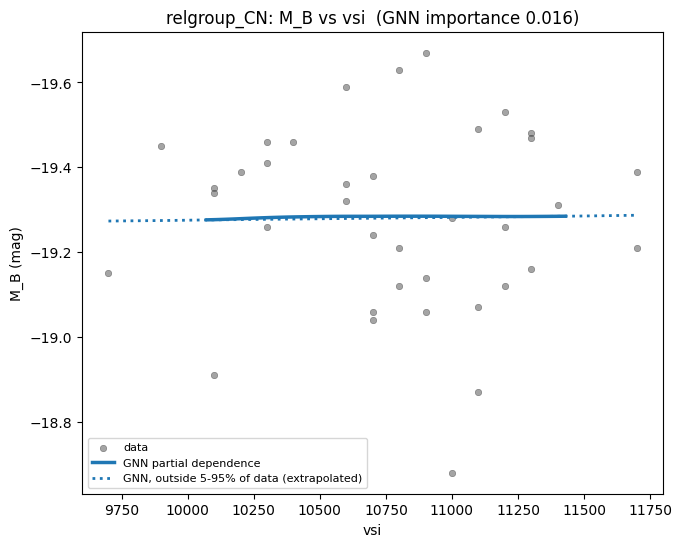

=== relgroup_CN_pew5972.png ===


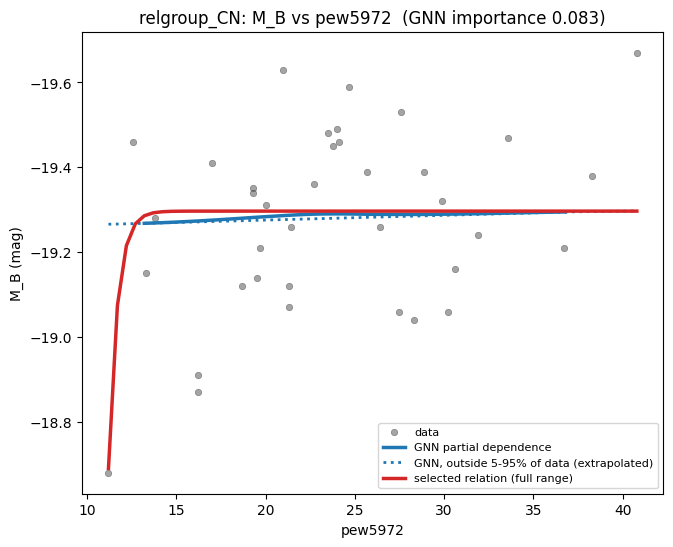

=== relgroup_CN_pew6355.png ===


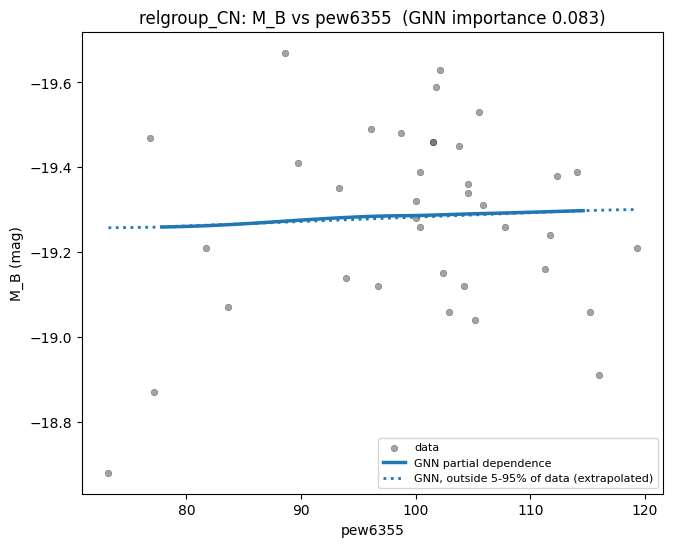

Branch group CL: n=18 is below 30, not tested


In [ ]:
# %% [Cell 8] Empirical relation search. The GNN is trained to predict M_B from the other parameters
# (target hidden from its input). Occlusion importance decides which parameters are candidates; the
# relation itself is then chosen by leave-one-out error on the data. Nothing is supplied in advance.


def select_relation(g, target, gate, cfg):
    """Greedy forward selection over (parameter, functional form), one term per parameter.
    Scored by leave-one-out RMSE on the observed SNe. The simplest form wins unless a more complex
    one improves error by >= min_rel_gain_step. Final terms need |t| >= 2.5."""
    cols = [target] + gate
    sub = g[cols].dropna().reset_index(drop=True)
    if len(sub) < 30:
        return dict(found=False, reason=f"only {len(sub)} SNe with {cols}")
    y = sub[target].to_numpy(float)
    n = len(y)
    loo_mean = (y.sum() - y) / (n - 1)
    base = np.sqrt(np.mean((y - loo_mean) ** 2))
    step = cfg.get("min_rel_gain_step", 0.02)
    order = ["x"] + [f for f in BASIS if f != "x"]
    per_pred = {}
    for p in gate:
        x = sub[p].to_numpy(float)
        best = None
        for f in order:
            fn, ok = BASIS[f]
            if not np.all(ok(x)):
                continue
            v = fn(x)
            if not (np.all(np.isfinite(v)) and np.std(v) > 1e-12):
                continue
            r = ols_loocv(v[:, None], y)["rmse_loo"]
            if best is None or r < best[0] * (1 - step):
                best = (r, f, v)
        if best is not None:
            per_pred[p] = best
    chosen, cur = [], base
    while len(chosen) < cfg.get("max_terms", 3):
        cand = None
        for p, (r0, f, v) in per_pred.items():
            if any(p == c[0] for c in chosen):
                continue
            X = np.column_stack([c[2] for c in chosen] + [v])
            r = ols_loocv(X, y)["rmse_loo"]
            if cand is None or r < cand[0]:
                cand = (r, p, f, v)
        if cand is None or cand[0] > cur * (1 - step):
            break
        chosen.append((cand[1], cand[2], cand[3])); cur = cand[0]
    while chosen:
        X = np.column_stack([np.ones(n)] + [c[2] for c in chosen])
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        resid = y - X @ beta
        s2 = np.sum(resid ** 2) / max(n - X.shape[1], 1)
        se = np.sqrt(np.diag(s2 * np.linalg.pinv(X.T @ X)))
        t = beta[1:] / (se[1:] + 1e-12)
        worst = int(np.argmin(np.abs(t)))
        if abs(t[worst]) >= 2.5:
            break
        chosen.pop(worst)
    if not chosen:
        return dict(found=False, reason="no term survives the leave-one-out and significance tests",
                    n=n, intercept_only_rmse_loo=float(base))
    X = np.column_stack([c[2] for c in chosen])
    fit = ols_loocv(X, y)
    gain = 1 - fit["rmse_loo"] / base
    b = fit["beta"]
    formula = f"{target} = {b[0]:+.3f} " + " ".join(
        f"{b[k + 1]:+.3f}*[{term_label(f, p)}]" for k, (p, f, _) in enumerate(chosen))
    found = bool(gain >= cfg.get("min_rel_gain", 0.10))
    return dict(found=found, formula=formula, terms=[(p, f) for p, f, _ in chosen], coefs=b.tolist(),
                n=n, rmse_loo=float(fit["rmse_loo"]), intercept_only_rmse_loo=float(base),
                gain=float(gain), r2_fit=float(fit["r2"]),
                reason="" if found else f"gain {100 * gain:.1f}% below {100 * cfg['min_rel_gain']:.0f}%")


def discover_relation(df, target, predictors, cfg, title):
    """Train the relation GNN ensemble, read it (importance, full-range partial dependence), select the relation."""
    for key, val in dict(importance_frac=0.25, max_terms=3, min_rel_gain=0.10, min_rel_gain_step=0.02,
                         grid_n=60, val_frac=0.20, seed=42, n_seeds=8, min_pair_n=10).items():
        cfg.setdefault(key, val)          # safe defaults if an older Cell 1 was run
    if not HAS_TORCH:
        print(f"[{title}] skipped: torch not available"); return None
    d = df.dropna(subset=[target]).reset_index(drop=True)
    nodes = [target] + predictors
    N = len(d)
    rng = np.random.default_rng(cfg.get("seed", 42))
    perm = rng.permutation(N)
    n_va = max(int(round(cfg.get("val_frac", 0.20) * N)), 5)
    va = np.zeros(N, bool); va[perm[:n_va]] = True
    tr = ~va
    G = build_graph_tensors(d, nodes, d[tr])
    S = pairwise_stats(d[tr], nodes)
    W = edge_weights(S, cfg.get("min_pair_n", 10))
    W[0, :] = 0.0; W[:, 0] = 0.0
    E = edge_features(S)
    models, vals = [], []
    for s in range(cfg.get("n_seeds", 8)):
        m, v = train_relation_gnn(G, W, E, cfg, cfg.get("seed", 42) + s, tr, va)
        models.append(m); vals.append(v)
    all_rows = np.arange(N)
    imp = occlusion_importance(models, G, W, E, all_rows, nodes)
    grids, curves, band = {}, {}, {}
    for p in predictors:
        v = d[p].dropna().to_numpy(float)
        lo, hi = v.min(), v.max()
        grids[p] = np.linspace(lo, hi, cfg.get("grid_n", 60))                 # FULL observed range
        curves[p] = partial_dependence(models, G, W, E, nodes.index(p), grids[p], all_rows)
        band[p] = np.quantile(v, [0.05, 0.95])
    imp = {p: float(imp[p]) for p in predictors}
    top = max(imp.values()) if imp else 0.0
    gate = [p for p in predictors if imp[p] >= cfg.get("importance_frac", 0.25) * top and top > 0]
    rel = select_relation(d, target, gate, cfg)
    print(f"\n[{title}] n={N} | GNN validation RMSE = {np.sqrt(np.mean(vals)) * G['sd'][0]:.3f} mag")
    print("  importance (GNN occlusion):", {p: round(v, 4) for p, v in sorted(imp.items(), key=lambda kv: -kv[1])})
    print("  candidates passed to selection:", gate)
    print("  relation:", rel.get("formula", "none"))
    print("  ", "FOUND" if rel.get("found") else "NOT FOUND -", rel.get("reason", ""))
    return dict(title=title, n=N, rel=rel, imp=imp, grids=grids, curves=curves, band=band, d=d, gate=gate)


def relation_partial(res, p):
    """Partial effect of parameter p in the selected relation, other terms held at their medians."""
    rel = res["rel"]
    if not rel.get("found") or p not in [t[0] for t in rel["terms"]]:
        return None
    d = res["d"]; grid = res["grids"][p]
    b = rel["coefs"]
    out = np.full(len(grid), b[0], float)
    for k, (q, f) in enumerate(rel["terms"]):
        if q == p:
            out += b[k + 1] * BASIS[f][0](grid)
        else:
            out += b[k + 1] * BASIS[f][0](np.full(len(grid), d[q].median()))
    return out


def show_discovery(res, prefix, invert=True):
    """One figure per predictor: data, GNN partial dependence (solid inside the 5-95% band, dotted outside),
    and the selected relation's partial effect over the full range."""
    if res is None:
        return
    for p, grid in res["grids"].items():
        fig, ax = plt.subplots(figsize=(7.5, 6))
        d = res["d"]
        ax.scatter(d[p], d["M_B"], s=22, alpha=0.55, color="0.35", edgecolor="k", lw=0.3, label="data")
        lo, hi = res["band"][p]
        inside = (grid >= lo) & (grid <= hi)
        cur = res["curves"][p]
        ax.plot(grid[inside], cur[inside], "-", color="tab:blue", lw=2.5, label="GNN partial dependence")
        ax.plot(grid[~inside], cur[~inside], ":", color="tab:blue", lw=2.0,
                label="GNN, outside 5-95% of data (extrapolated)")
        rp = relation_partial(res, p)
        if rp is not None:
            ax.plot(grid, rp, "-", color="tab:red", lw=2.5, label="selected relation (full range)")
        ax.set(xlabel=p, ylabel="M_B (mag)", title=f"{prefix}: M_B vs {p}  (GNN importance {res['imp'][p]:.3f})")
        if invert:
            ax.invert_yaxis()
        ax.legend(fontsize=8)
        show(fig, f"{prefix}_{p}.png")


R_ALL = discover_relation(DATA, "M_B", ["vsi", "pew5972", "pew6355"], CFG, "all 133 SNe")
R_SBV = discover_relation(DATA[DATA.sBV.notna()], "M_B", ["sBV", "pew5972", "vsi", "pew6355"], CFG,
                          "97 CSP SNe with s_BV")
show_discovery(R_ALL, "relall")
show_discovery(R_SBV, "relsbv")

# Comparison: the quadratic the paper fits (ordinary least squares), leave-one-out on the same SNe
q = DATA.dropna(subset=["M_B", "pew5972"]).reset_index(drop=True)
quad = ols_loocv(np.column_stack([q.pew5972, q.pew5972 ** 2]), q.M_B.to_numpy(float))
print(f"\nPaper-style quadratic in pEW(5972): LOOCV RMSE = {quad['rmse_loo']:.3f} mag")
for name, R in [("all 133 SNe", R_ALL), ("97 CSP with s_BV", R_SBV)]:
    if R is not None and R["rel"].get("found"):
        print(f"Selected relation, {name}: LOOCV RMSE = {R['rel']['rmse_loo']:.3f} mag "
              f"(intercept-only {R['rel']['intercept_only_rmse_loo']:.3f}, gain {100 * R['rel']['gain']:.1f}%)")

# Observed vs predicted, selected relation (all SNe)
if R_ALL is not None and R_ALL["rel"].get("found"):
    d = R_ALL["d"].dropna(subset=[p for p, _ in R_ALL["rel"]["terms"]])
    b = R_ALL["rel"]["coefs"]
    pred = b[0] + sum(b[k + 1] * BASIS[f][0](d[p].to_numpy(float)) for k, (p, f) in enumerate(R_ALL["rel"]["terms"]))
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.scatter(pred, d["M_B"], s=28, edgecolor="k", lw=0.4, color="tab:blue")
    lim = [min(pred.min(), d.M_B.min()), max(pred.max(), d.M_B.max())]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(xlabel="predicted M_B from selected relation (mag)", ylabel="observed M_B (mag)",
           title="Observed vs predicted, all SNe")
    ax.invert_xaxis(); ax.invert_yaxis()
    show(fig, "relall_observed_vs_predicted.png")

# Relation within each Branch group, groups with at least 30 SNe
R_GROUP = {}
for nm in pd.unique(RUN["FULL4D"]["names"]):
    sub = DATA[np.asarray(RUN["FULL4D"]["names"]) == nm]
    if len(sub) >= 30:
        R_GROUP[nm] = discover_relation(sub, "M_B", ["vsi", "pew5972", "pew6355"], CFG, f"Branch group {nm}")
        show_discovery(R_GROUP[nm], f"relgroup_{nm}")
    else:
        print(f"Branch group {nm}: n={len(sub)} is below 30, not tested")


In [ ]:
# %% [Cell 9] Save results, index of figures, download
summary = dict(
    source="Burrow et al. 2020 Table 1 (133 SNe Ia), embedded in this notebook",
    method="GNN only (no mixture models); spectral clustering on GNN seed co-association",
    torch_used=bool(HAS_TORCH), device=DEVICE, seeds=CFG["n_seeds"],
    clusters={k: pd.Series(RUN[k]["names"]).value_counts().to_dict() for k in RUN},
    relation_all=None if R_ALL is None else R_ALL["rel"],
    relation_sbv=None if R_SBV is None else R_SBV["rel"],
    relation_by_group={k: (None if v is None else v["rel"]) for k, v in R_GROUP.items()},
    quadratic_paper_style_loocv_rmse=float(quad["rmse_loo"]),
)
with open(os.path.join(CFG["out_dir"], "summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)
DATA.to_csv(os.path.join(CFG["out_dir"], "burrow2020_table1_with_errors.csv"), index=False)
for k in RUN:
    out = DATA[["name", "survey", "M_B", "vsi", "pew5972", "pew6355"]].copy()
    out["group"] = RUN[k]["names"]
    out.to_csv(os.path.join(CFG["out_dir"], f"groups_{k}.csv"), index=False)
pngs = sorted(f for f in os.listdir(CFG["out_dir"]) if f.endswith(".png"))
print(f"{len(pngs)} figures saved:")
for f in pngs:
    print("  ", f)
# Save the code itself next to the results, so it can be downloaded as well
import shutil
src_path = os.path.join(CFG["out_dir"], "burrow2020_gnn_replication_code.py")
with open(src_path, "w", encoding="utf-8") as f:
    f.write("\n\n".join(["# Burrow et al. 2020 GNN replication (generated notebook source)"]
                          + [open(p, encoding="utf-8").read() for p in
                             ["c1_setup.py", "c2_data.py", "c3_utils.py", "c4_gnn.py", "c5_cluster.py",
                              "c6_figs.py", "c7_mbvsi_sbv.py", "c8_relations.py", "c9_save.py"]
                             if os.path.exists(p)]))
zip_path = "/content/burrow_gnn_outputs.zip" if os.path.isdir("/content") else "burrow_gnn_outputs.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for fn in sorted(os.listdir(CFG["out_dir"])):
        z.write(os.path.join(CFG["out_dir"], fn), arcname=fn)
print("Archive:", os.path.abspath(zip_path), f"({os.path.getsize(zip_path) // 1024} KB)")
print("Code file:", os.path.abspath(src_path))
try:
    from google.colab import files
    for path in [zip_path, src_path]:
        files.download(path)
    print("Download started for the archive and the code file.")
except ImportError:
    print("Not running in Colab: find the files in", os.path.abspath(CFG["out_dir"]))


37 figures saved:
   fig02a_silhouette.png
   fig02b_stability.png
   fig03_branch_data.png
   fig04_branch_gnn2d.png
   fig05a_branch_3d_vsi.png
   fig05b_pew5972_vsi_3d.png
   fig06a_branch_3d_mb.png
   fig06b_mb_pew5972_3d.png
   fig07_mb_pew5972_quadratic.png
   fig08a_branch_4d.png
   fig08b_pew5972_vsi_4d.png
   fig08c_mb_pew5972_4d.png
   fig09_mb_vsi_data.png
   fig10_mbvsi_gnn.png
   fig11_branch_by_mbvsi.png
   fig16_mbvsi_4d.png
   fig17a_mb_sbv_branch.png
   fig17b_mb_sbv_mbvsi.png
   fig18_branch_sbv.png
   fig19_pew5972_sbv.png
   relall_observed_vs_predicted.png
   relall_pew5972.png
   relall_pew6355.png
   relall_vsi.png
   relgroup_BL_pew5972.png
   relgroup_BL_pew6355.png
   relgroup_BL_vsi.png
   relgroup_CN_pew5972.png
   relgroup_CN_pew6355.png
   relgroup_CN_vsi.png
   relgroup_SS_pew5972.png
   relgroup_SS_pew6355.png
   relgroup_SS_vsi.png
   relsbv_pew5972.png
   relsbv_pew6355.png
   relsbv_sBV.png
   relsbv_vsi.png
Archive: /content/burrow_gnn_outputs.zip (3

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started for the archive and the code file.
